# AIRBNB — Báo cáo dữ liệu và thiết kế nghiên cứu propensity

**Phạm vi:** notebook phân tích mô tả dữ liệu gốc, gồm nhãn y, độ trễ và các nhóm đăng ký theo thời gian. Báo cáo đề xuất thiết kế thí nghiệm cho giai đoạn tiếp theo. Mọi số liệu là thống kê mô tả, chưa phải kết quả mô hình hoặc bằng chứng về tác động nhân quả.

Bảng thuật ngữ và tóm tắt điều hành nằm ở đầu phần kết quả. Các bảng chi tiết được chuyển xuống phụ lục để thuận tiện tra cứu.

Notebook đã lưu kết quả để đọc trực tiếp. Hướng dẫn chuẩn bị dữ liệu, cài môi trường và chạy lại được đặt ở mục **Tái lập và kiểm soát phạm vi** cuối báo cáo. Notebook cần mã trong thư mục scripts/ và dữ liệu CSV của dự án để chạy lại.

Quy ước số: dấu chấm biểu diễn phần thập phân; dấu phẩy phân tách hàng nghìn. Tên cột và mã giá trị được giữ nguyên trong từ điển dữ liệu để đối chiếu với CSV.


In [1]:
from pathlib import Path
import importlib
import sys
from datetime import datetime
from zoneinfo import ZoneInfo

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / 'scripts' / 'build_descriptive_reports.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Notebook cần package scripts/ của dự án; xem cấu trúc thư mục trong ô mở đầu.')
required = [PROJECT_ROOT / 'scripts' / name for name in
            ['__init__.py', 'build_descriptive_reports.py', 'eda_diagnostics.py', 'airbnb_deep_dive.py', 'airbnb_report_presentation.py', 'airbnb_research_revision.py']]
required += [PROJECT_ROOT / 'data' / 'raw' / 'AIRBNB' / name for name in
             ['train_users_2.csv', 'test_users.csv', 'sessions.csv', 'countries.csv', 'age_gender_bkts.csv']]
missing = [str(p.relative_to(PROJECT_ROOT)) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError('Thiếu file để chạy lại Airbnb: ' + ', '.join(missing))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts import build_descriptive_reports as eda
importlib.reload(eda)
report = eda.build_report('AIRBNB', PROJECT_ROOT)
print('Ngày tính lại (Asia/Ho_Chi_Minh):', datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).isoformat())
print('Đã tính EDA từ CSV raw; số chính:', report.facts)
print('Không tạo tập feature, tập chia hoặc mô hình. Ngày tải: không được lưu; snapshot theo SHA-256.')


Ngày tính lại (Asia/Ho_Chi_Minh): 2026-11-02T12:20:30.629131+07:00
Đã tính EDA từ CSV raw; số chính: {'rows': 213451, 'columns': 16, 'positive': 88908, 'rate': 0.4165265095970504, 'sessions': 10567737, 'session_users': 135483, 'train_session_users': 73815, 'test_session_users': 61668, 'test_rows': 62096, 'sessions_missing_ids': 34496, 'figure_seed': 42, 'rules_checked_on': '2026-11-01', 'download_date_status': 'unknown_no_documentary_evidence', 'dataset_version_status': 'unknown_kaggle_version_local_snapshot_identified', 'local_snapshot_sha256': '45e506f76002c40e6710fe27864a365bd0476ceae98e4e2803d7bd239c01114c', 'valid_booking_lags': 88879, 'negative_booking_lags': 29, 'booking_coverage_30_pct': 75.32713014322844, 'booking_coverage_60_pct': 80.25855376410625, 'booking_coverage_90_pct': 83.2896409725582, 'max_observed_booking_lag_days': 365, 'train_2014_users': 76466, 'train_2014_session_users': 73815, 'train_2014_session_coverage_pct': 96.5330996782884, 'session_action_audit_names': 59

## Thuật ngữ và cách đọc báo cáo

In [2]:
eda.show_section(report, 'glossary')

Mọi số liệu trong báo cáo là thống kê mô tả từ dữ liệu gốc. Chúng cho biết các liên hệ trong mẫu, chưa phải kết quả dự báo hoặc bằng chứng về tác động nhân quả. Báo cáo dừng ở EDA và thiết kế thí nghiệm, chưa xử lý dữ liệu cho mô hình hoặc huấn luyện mô hình.

Báo cáo dùng thống nhất “nhãn y” cho kết quả gốc và “nhãn y90” cho mục tiêu nghiên cứu 90 ngày và “lượt đặt chỗ đầu tiên” cho hành vi cần dự đoán. Tên cột và mã giá trị được giữ nguyên để đối chiếu với dữ liệu.

Quy ước số: dấu chấm biểu diễn phần thập phân; dấu phẩy phân tách hàng nghìn. Tên cột gốc chỉ dùng khi cần đối chiếu dữ liệu.

**Các thuật ngữ dùng trong báo cáo**

| Thuật ngữ | Giải nghĩa |
| --- | --- |
| EDA | Phân tích khám phá dữ liệu bằng bảng, biểu đồ và thống kê mô tả. |
| NDF | Mã No Destination Found trong country_destination, nghĩa là bộ dữ liệu không ghi nhận lượt đặt chỗ. Mã này không có nghĩa người dùng sẽ không bao giờ đặt chỗ. |
| Nhãn y | Mục tiêu nhị phân: y=1 nếu country_destination khác NDF, y=0 nếu bằng NDF. Cột country_destination giữ nguyên 12 giá trị điểm đến gốc. |
| Lượt đặt chỗ đầu tiên | Lượt đặt chỗ đầu tiên được ghi nhận trong bộ dữ liệu (first booking). |
| t0 | Thời điểm dự đoán, được chọn là ngay sau khi người dùng hoàn tất tạo tài khoản. |
| Thời hạn dự đoán (horizon) | Khoảng thời gian tính từ t0 để xét hành vi, chẳng hạn 90 ngày. Thời gian theo dõi thực tế của nhãn y hiện có còn cần xác minh. |
| Nhóm đăng ký (cohort) | Những người tạo tài khoản trong cùng một khoảng thời gian, thường là một tháng hoặc một năm. |
| Rò rỉ thông tin (leakage) | Việc dùng thông tin tiết lộ kết quả hoặc chưa có sẵn tại t0 làm đầu vào dự đoán. |
| Cramér V | Thước đo độ mạnh liên hệ giữa hai biến phân loại, từ 0 (không liên hệ) đến 1 (liên hệ hoàn toàn). |
| Rank-biserial | Thước đo chênh lệch thứ hạng giữa hai nhóm, từ −1 đến 1. Với tuổi, dấu dương nghĩa nhóm y=1 có xu hướng lớn tuổi hơn. Giá trị gần 0 nghĩa khác biệt rất nhỏ. |
| Khoảng Wilson 95% | Khoảng tin cậy cho tỷ lệ trong một nhóm. Khoảng rộng cho biết ước lượng còn kém chính xác, thường do nhóm ít người. |
| Sessions | Nhật ký hoạt động trên web hoặc ứng dụng. Mỗi người dùng có thể có nhiều sự kiện. |
| Train / test | Tập có nhãn dùng cho nghiên cứu / tập Kaggle không có nhãn, dùng đối chiếu cấu trúc và phân phối. |
| NA / unknown / untracked | Giá trị bị thiếu / mã không rõ thông tin / mã không theo dõi được. Báo cáo giữ riêng ba trường hợp. |
| Mốc bắt đầu dự đoán (origin) | Thời điểm lịch bắt đầu một lượt đánh giá. Dữ liệu dùng huấn luyện phải có sẵn trước mốc này. |
| Nhãn y90 | Nhãn nghiên cứu 90 ngày có điều kiện: 1 nếu độ trễ từ 0 đến 90; 0 nếu muộn hơn hoặc NDF dưới giả định theo dõi đủ 365 ngày. Ngoại lệ ngày âm chưa gán nhãn. |
| Khoảng đệm thời gian (embargo) | Khoảng ngày đăng ký bị bỏ khỏi tập trước để nhãn 90 ngày hoàn tất trước khi dự đoán tập sau. Ở đây đệm 90 ngày lịch và chỉ dùng nhãn đã có trước mốc dự đoán. |

## Tóm tắt điều hành

In [3]:
eda.show_section(report, 'executive')

**Kết luận:** có thể nghiên cứu xác suất đặt chỗ trong 90 ngày bằng nhãn có điều kiện dưới giả định theo dõi đủ 365 ngày. Thiết kế đánh giá dùng khoảng đệm theo ngày lịch và đối chứng Logistic Regression mạnh để kiểm tra giá trị bổ sung của CatBoost. (Nguồn: bảng B9 và B7.)

**Năm phát hiện chính**

1. **Quy mô và nhãn y:** tập train có 213,451 người dùng, trong đó 88,908 người có lượt đặt chỗ đầu tiên (41.65%). Tập test có 62,096 người dùng. Hai nhóm nhãn y có quy mô đủ lớn để bắt đầu thí nghiệm với phân phối lớp hiện có. (Nguồn: bảng B1.)

2. **Nhãn nghiên cứu 90 ngày có điều kiện:** có 74,027 người đặt chỗ trong 90 ngày, bằng 34.68% toàn bộ 213,451 dòng. Với giả định theo dõi đủ 365 ngày và loại 29 ngoại lệ chưa gán, mẫu nghiên cứu còn 213,422 người, tỷ lệ dương 34.69%. Đây là tỷ lệ trên toàn bộ mẫu người dùng tương ứng, khác với mức bao phủ trong nhóm đã đặt chỗ. (Nguồn: bảng B9.)

3. **Tín hiệu chung về độ đầy đủ hồ sơ:** trong năm 2014, FEMALE và MALE có tỷ lệ nhãn y=1 gần như nhau (50.84% và 50.95%). Nhóm không rõ giới tính có tỷ lệ 26.54%. Người có tuổi đạt 54.54%, so với 18.01% ở người thiếu tuổi. Hai cờ thiếu hồ sơ có V=0.783, nên đây là tín hiệu chồng lặp cần kiểm tra giá trị bổ sung, không phải hai phát hiện dự báo độc lập. Cả hai chỉ được dùng sau khi xác minh tại t0. (Nguồn: bảng B10.)

4. **Chênh lệch ứng dụng sau phân tầng hồ sơ:** trong nhóm năm 2014 có tuổi và có khai báo giới tính, tỷ lệ nhãn y=1 của Web là 54.73%, iOS 39.56% và Android 39.85%. Chênh lệch vẫn hiện diện sau khi tách hai cờ hồ sơ. Bảng chi tiết báo cả nhãn y và y90 cùng cỡ mẫu; kết quả vẫn là mô tả và chưa kiểm soát mọi khác biệt. (Nguồn: bảng B11.)

5. **Phạm vi nhật ký hoạt động:** trong năm 2014, 96.53% người dùng train và 99.31% người dùng test có sessions, chênh 2.78 điểm phần trăm. Tỷ lệ có đặt chỗ trong nhóm có nhật ký là 38.98%, so với 17.54% ở nhóm thiếu nhật ký. Vì dữ liệu trước năm 2014 không có sessions, nghiên cứu riêng nguồn này cần tập trung vào 76,466 người dùng train đăng ký năm 2014. (Nguồn: bảng B5.)

**Ba việc cần giải quyết trước khi huấn luyện**

1. **Chốt giả định nhãn và xử lý ngoại lệ.** Cho phép nghiên cứu y90 dưới giả định theo dõi đủ 365 ngày, báo độ nhạy khi không gán âm cho NDF và giữ 29 ngoại lệ ngoài mẫu y90. Q3 cần xác nhận chính thức trước triển khai, thay vì chặn toàn bộ nghiên cứu có điều kiện. (Nguồn: bảng B9 và Q3.)

2. **Chốt thông tin có sẵn tại t0.** Xác minh hồ sơ và các cờ thiếu phản ánh lúc đăng ký. Loại ngày đặt chỗ và cờ thiếu của cột này khỏi đầu vào vì mức khớp nhãn y là 100%. Nhật ký thiếu thời điểm sự kiện vẫn ngoài thiết kế chính. (Nguồn: bảng B8 và Q1.)

3. **Dùng đối chứng mạnh và khoảng đệm.** Chọn cấu hình cùng LR đối chứng trên các lượt kiểm định có đệm 90 ngày. Huấn luyện lại đến 2013-10-02, hiệu chỉnh trên 2014-01-01 đến 2014-01-30, rồi đánh giá tháng 5–6/2014. CatBoost phải tăng giá trị so với LR trên cùng nhãn y90 và cùng cửa sổ, không chỉ vượt xác suất hằng. (Nguồn: bảng B7.)

## 1. Bài toán và lý do chọn dữ liệu

In [4]:
eda.show_section(report, 'problem')

Bài toán nghiên cứu chính là ước lượng xác suất người dùng mới có lượt đặt chỗ đầu tiên trong 90 ngày kể từ lúc đăng ký. Thời điểm dự đoán t0 là ngay sau khi tạo tài khoản.

Nhãn y90 được xây dựng có điều kiện dưới giả định mỗi người được theo dõi đủ 365 ngày. Cột điểm đến gốc vẫn xác định nhãn y để mô tả bộ dữ liệu; y và y90 là hai mục tiêu khác nhau. Các bảng EDA cũ tiếp tục ghi rõ nhãn y, còn thiết kế mô hình và bảng B7 dùng y90. Quy tắc và mẫu số của y90 nằm ở B9.

Thông tin đầu vào chỉ hợp lệ nếu phản ánh hồ sơ tại t0. Các cột ngày đặt chỗ, cờ thiếu ngày đặt chỗ và nhật ký chưa có thời điểm sự kiện bị loại khỏi thiết kế chính. Các ngoại lệ ngày đặt chỗ âm được giữ trong EDA nhãn y nhưng chưa gán y90.

**Lý do chọn Airbnb so với hai bộ còn lại**

| Bộ dữ liệu | Đơn vị | Bằng chứng | Mức phù hợp | Quyết định |
| --- | --- | --- | --- | --- |
| AIRBNB | User mới | 213,451 user; 41.65% có booking | Đúng đối tượng chấm propensity khách hàng; có ID | Chọn cho nghiên cứu, còn điều kiện nhãn/t0 |
| HOTEL | Booking đã được tạo | Nhãn hủy/no-show; không quan sát đầy đủ người chưa đặt | Hợp cancellation propensity | Không trả lời trực tiếp ai sẽ tạo lượt đặt chỗ đầu tiên |
| EXPEDIA | Cặp search–hotel | Tương tác trong danh sách; thiếu user ID và search không click | Hợp ranking/propensity trong search | Không ưu tiên cho propensity onboarding theo user |

## 2. Tổng quan bộ dữ liệu

### Nguồn gốc và phạm vi thu thập

Nguồn công bố: [trang dữ liệu/nghiên cứu gốc](https://www.kaggle.com/c/airbnb-recruiting-new-user-bookings/data). [Giấy phép/điều khoản và trang phân phối](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/rules). Báo cáo ghi rõ những thông tin chưa được lưu hoặc chưa xác minh.

**Thông tin nguồn và phiên bản**

| Nội dung | Mô tả |
| --- | --- |
| Tên / nơi công bố | Airbnb / Kaggle — Airbnb New User Bookings |
| Năm công bố | Cuộc thi công bố 2015, kết thúc 2016 |
| Mục đích thu thập/công bố | Dự đoán quốc gia của lượt đặt chỗ đầu tiên cho người dùng mới để cá nhân hóa nội dung. |
| Cách thu thập / quần thể | Dữ liệu gồm hồ sơ đăng ký, nhật ký web/ứng dụng và các bảng tổng hợp của người dùng từ Mỹ. CSV chưa lưu chi tiết cách chọn người dùng và ngày kết thúc theo dõi của từng người. |
| Thời gian bao phủ quan sát được | Account train 2010-01-01–2014-06-30; test 2014-07-01–2014-09-30 |
| Ngày tải raw | Chưa có bằng chứng trong hồ sơ dự án về ngày tải hoặc mã phiên bản Kaggle. Bản dữ liệu được nhận diện bằng SHA-256. |
| Quy mô bảng train/chính | 213,451 dòng × 16 cột thô |
| Dung lượng mọi CSV của bộ hiện có | 664,207,331 byte = 633.44 MiB; gồm cả bảng phụ/benchmark nếu có |
| Phiên bản local | Nhận diện bằng tên file, bytes, số dòng và SHA-256 tại phụ lục |
| Giấy phép / điều khoản | Competition Rules, không phải giấy phép mở CC0/CC BY. Điều khoản DATA có giới hạn mục đích sử dụng và phân phối; phải đối chiếu rules trước khi tái sử dụng hoặc công bố dữ liệu. |

**B1 · Quy mô người dùng và nhãn y**

| Tập dữ liệu | Số người dùng | Số có nhãn y=1 | Tỷ lệ y=1 (%) |
| --- | --- | --- | --- |
| Train | 213,451 | 88,908 | 41.6527 |
| Test | 62,096 | — | — |

### Bối cảnh, đơn vị quan sát và phạm vi nhãn

Train gồm **213,451 người dùng, 16 cột**, test gồm **62,096 người dùng, 15 cột**. Cột `country_destination` có 12 giá trị, gồm `NDF` và 11 điểm đến hoặc nhóm điểm đến. Báo cáo định nghĩa nhãn y từ cột này để phân tích khả năng có lượt đặt chỗ đầu tiên ở cấp người dùng.

Mục tiêu gốc của bộ dữ liệu là dự đoán điểm đến của lượt đặt chỗ đầu tiên. Nhãn y kế thừa phạm vi theo dõi của bộ dữ liệu. Phần 5 phân tích độ trễ và thông tin cần bổ sung để xây dựng nhãn cho thời hạn 30, 60 hoặc 90 ngày.

[Mô tả cuộc thi Airbnb New User Bookings](https://www.kaggle.com/c/airbnb-recruiting-new-user-bookings/data) nêu người dùng trong tập đến từ Mỹ. Vì vậy tính đại diện về địa lý, thời kỳ và sản phẩm có giới hạn. Test công khai không có nhãn để tính chất lượng dự đoán hoặc so sánh tỷ lệ đặt chỗ với train.

### Quan hệ giữa các bảng

Hồ sơ người dùng là đơn vị phân tích chính. Khi ghép nhật ký một–nhiều, phải tổng hợp về một dòng mỗi người trước khi xây dựng dữ liệu học. Hai bảng phụ mô tả điểm đến và dân số tổng hợp, nên cần phân biệt quan hệ có thể tra cứu với khóa đã biết tại thời điểm dự đoán.

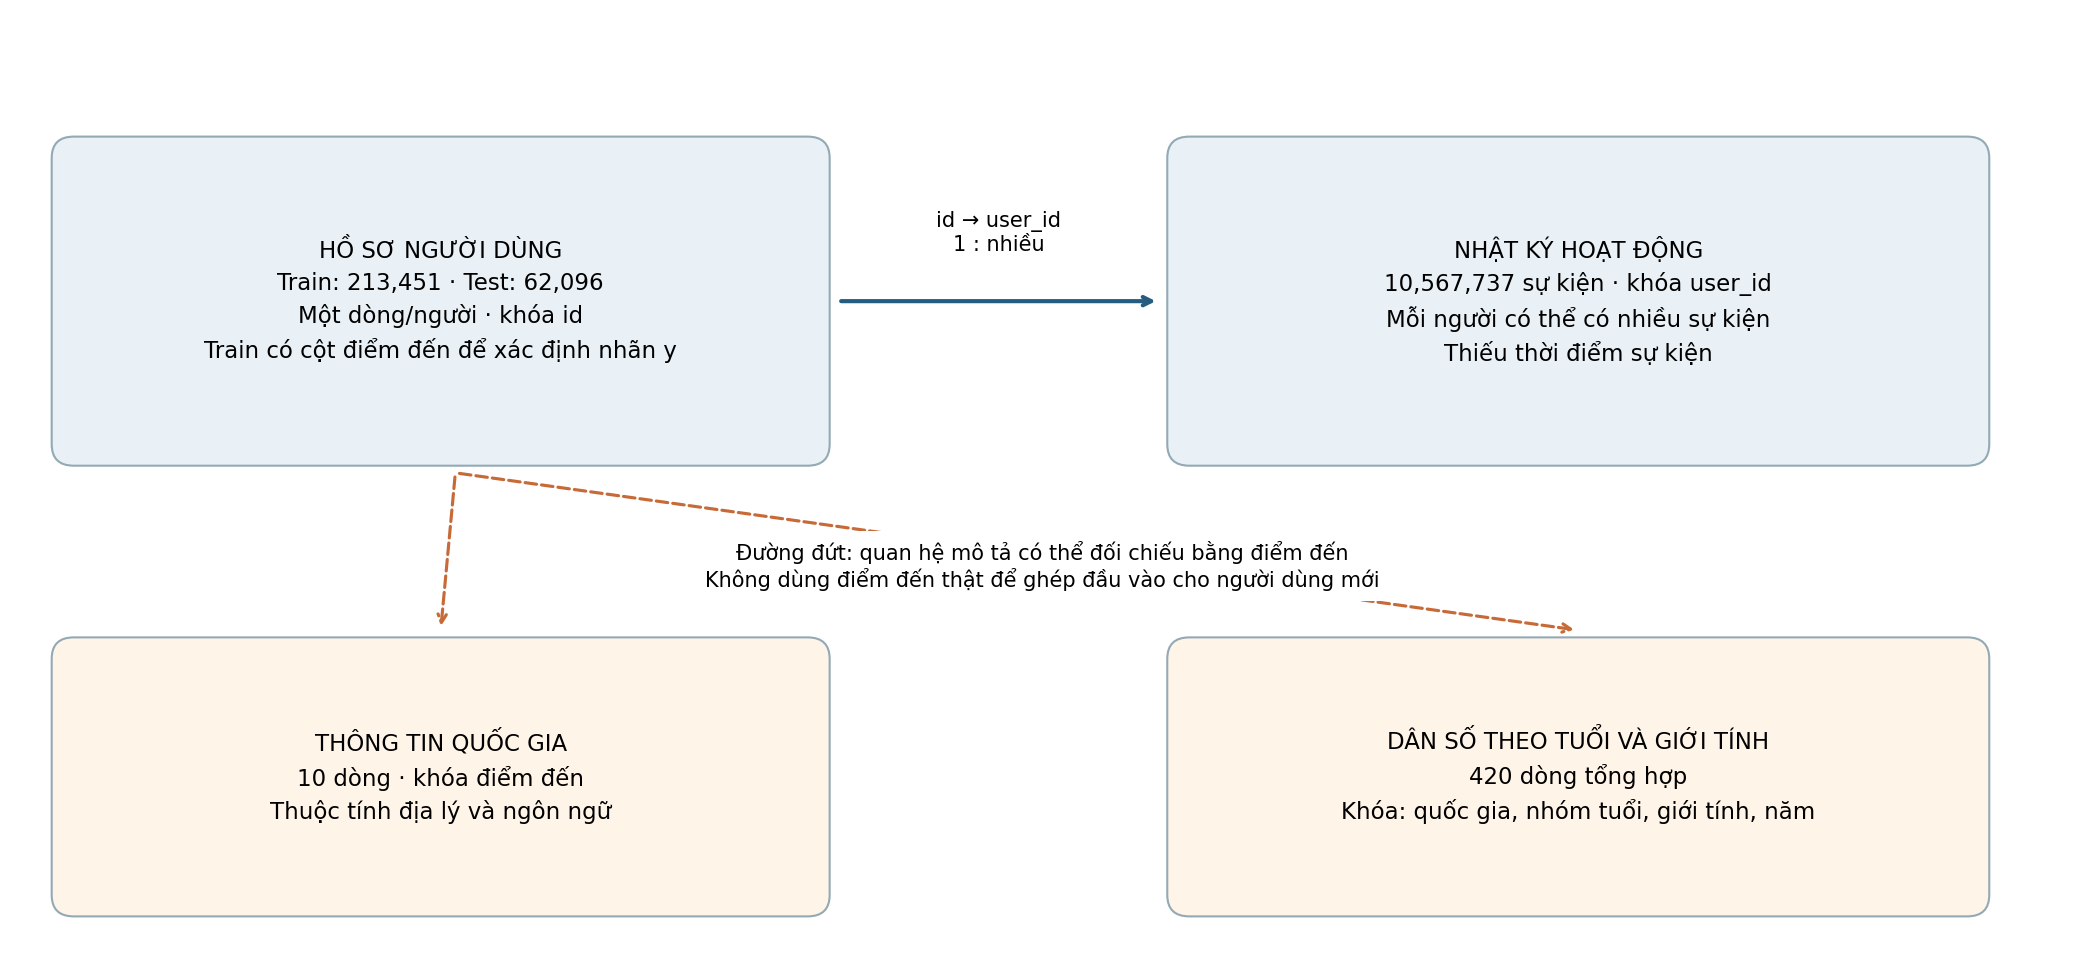

**Quan sát:** hồ sơ có thể ghép với nhật ký qua định danh. Có 34,496 sự kiện thiếu định danh nên không ghép được về người dùng.

**Phạm vi và cách đọc:** mũi tên liền chỉ quan hệ khóa 1:nhiều. Mũi tên đứt chỉ quan hệ bối cảnh, chưa phải phép ghép được chấp nhận cho mô hình. Các con số là quy mô bảng, không phải số khách hàng bổ sung.

In [5]:
eda.show_section(report, 'overview')

## 3. Chất lượng dữ liệu

### Chất lượng users, sentinel và rò rỉ nhãn

**Rò rỉ đã kiểm chứng:** việc `date_first_booking` có giá trị hay bị thiếu khớp nhãn y ở **100.00%** người dùng train. Vì cột này tiết lộ kết quả cần dự đoán, thiết kế đầu vào loại cả ngày đặt chỗ và cờ thiếu ngày đặt chỗ. Giá trị thiếu ở đây phản ánh cách ghi nhận kết quả nên không cần điền ngày thay thế.

Tuổi ngoài [16; 100] được thống kê riêng theo một **dải tham chiếu dùng cho EDA**. Các giá trị dạng 19xx/20xx gợi ý khả năng người dùng đã nhập năm sinh. Cần xác minh cách thu thập trước khi quyết định chuyển đổi hoặc thay thế tuổi. Các mã đặc biệt trong gender và browser được thống kê riêng với giá trị thiếu NA.

Người dùng có thể tìm kiếm trước khi đăng ký, nên ngày hoạt động đầu có thể sớm hơn ngày tạo tài khoản. Có **29** dòng ghi ngày đặt chỗ trước ngày tạo tài khoản. Những trường hợp này cần được đối chiếu với định nghĩa các mốc thời gian trước khi quyết định đưa vào tập huấn luyện.

**Kiểm tra định danh và logic thời gian**

| Nội dung kiểm tra | Số người dùng |
| --- | --- |
| ID train bị lặp (beyond first) | 0 |
| ID test bị lặp (beyond first) | 0 |
| ID xuất hiện ở cả train và test | 0 |
| date_first_booking.notna không khớp nhãn có booking | 0 |
| date_first_booking có giá trị trong test | 0 |
| Tuổi có giá trị nhưng ngoài [16; 100] (quy ước mô tả) | 2,410 |
| Lượt đặt chỗ đầu tiên trước ngày tạo tài khoản | 29 |
| Hoạt động đầu trước ngày tạo tài khoản | 178 |
| Ngày account không parse được | 0 |
| Timestamp hoạt động đầu không parse được | 0 |
| Ngày booking có giá trị nhưng không parse được | 0 |

**NA và giá trị đặc biệt là các khái niệm khác nhau**

| Cột gốc | null n | minus unknown n | untracked n |
| --- | --- | --- | --- |
| gender | 0 | 95,688 | 0 |
| first_browser | 0 | 27,266 | 0 |
| first_affiliate_tracked | 6,065 | 0 | 109,232 |

... (4 outputs left out)

### Missing có quy luật hay không?

Heatmap chọn tối đa 12 cột có NA. Chọn dòng để hiển thị với seed=42 và sắp theo pattern; bảng tỷ lệ theo nhóm dùng quần thể phân tích công bố, không chỉ các dòng hiển thị.

**Missing (%) theo account year; toàn bộ users train AIRBNB**

| Năm đăng ký | Ngày đặt chỗ đầu tiên | Tuổi khai báo | Tương tác tiếp cận đầu tiên |
| --- | --- | --- | --- |
| 2010 | 42.5036 | 38.8092 | 28.1564 |
| 2011 | 45.3673 | 34.7346 | 20.3227 |
| 2012 | 55.0226 | 34.8183 | 3.312 |
| 2013 | 59.1562 | 42.1287 | 0.9462 |
| 2014 | 61.7621 | 44.6316 | 1.0397 |

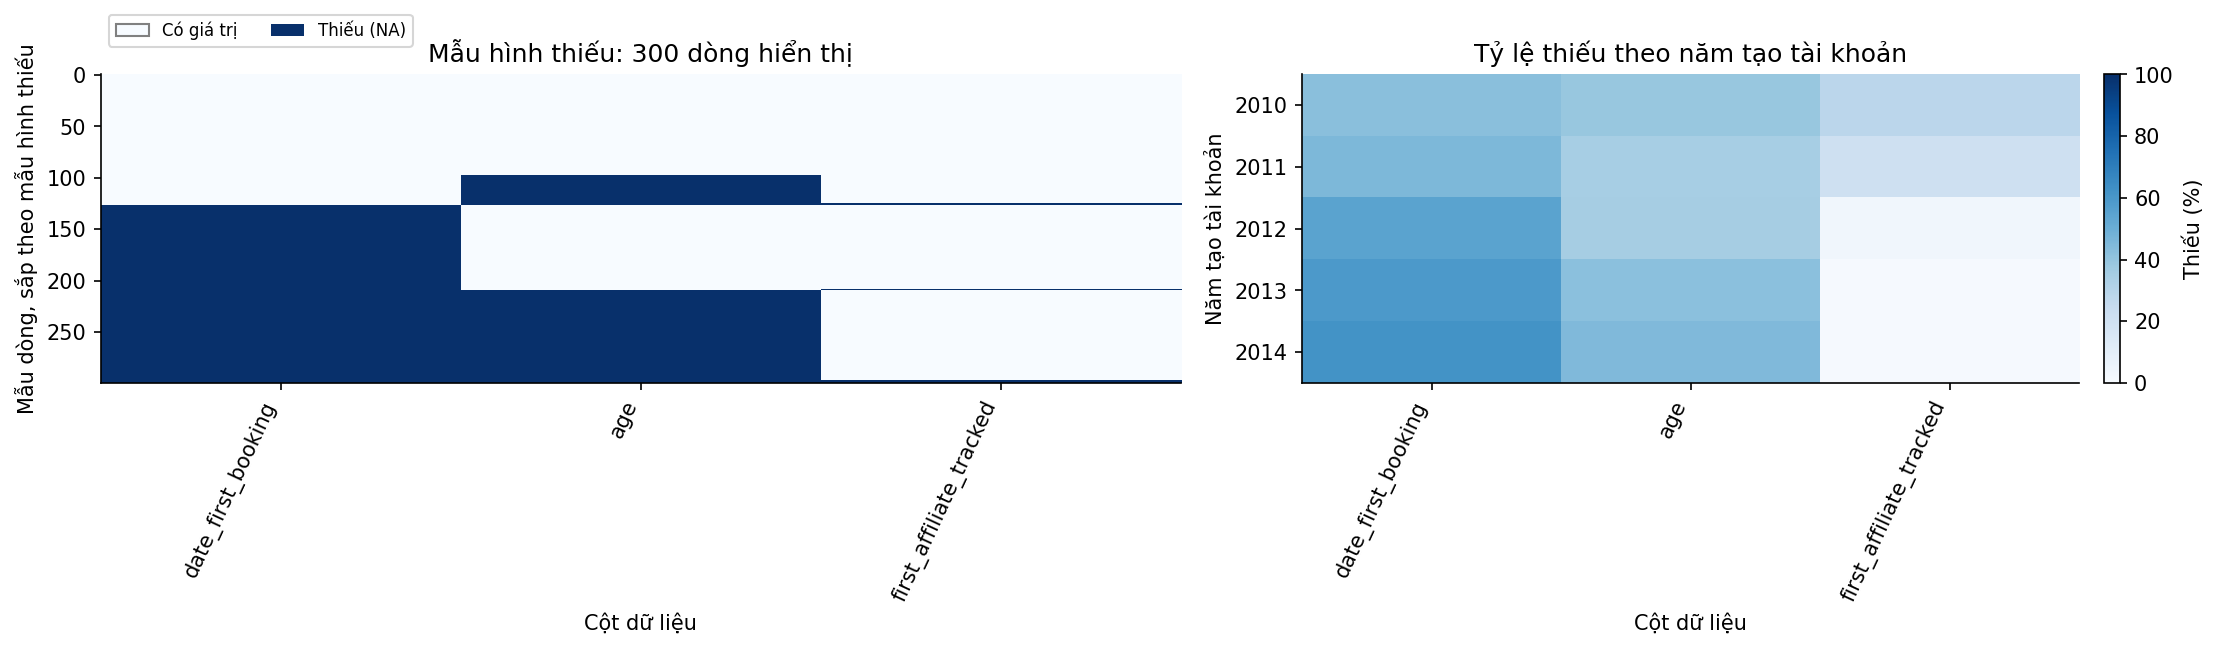

**Quan sát:** date_first_booking thiếu 58.35% trong toàn bộ users train AIRBNB; chênh lệch missing lớn nhất giữa các nhóm account year là 27.21 điểm phần trăm ở first_affiliate_tracked. Ô xanh là NA. Mẫu dòng hiển thị dùng seed=42; việc sắp theo pattern chỉ để nhìn cụm thiếu, không phải thứ tự thời gian. Các khác biệt này không đủ kết luận cơ chế MCAR/MAR/MNAR.

**Phạm vi và cách đọc:** Bảng tỷ lệ dùng toàn bộ train; hình mẫu thiếu chỉ hiển thị tối đa 300 dòng, seed=42.

### Ngoại lai: lượng hóa và phân biệt quy tắc với kết luận lỗi

Quy tắc 1.5×IQR chỉ gắn cờ để kiểm tra, không tự chứng minh lỗi. Mẫu số là số giá trị không thiếu của từng cột; bảng giữ rõ quần thể và trường hợp IQR=0.

**Hàng rào IQR trên dữ liệu công bố**

| Cột gốc | population | nonnull n | q1 | q3 | iqr | lower fence | upper fence | flagged n | flagged pct nonnull | iqr zero |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| age | toàn bộ users train AIRBNB | 125,461 | 28 | 43 | 15 | 5.5 | 65.5 | 5,594 | 4.4588 | 0 |

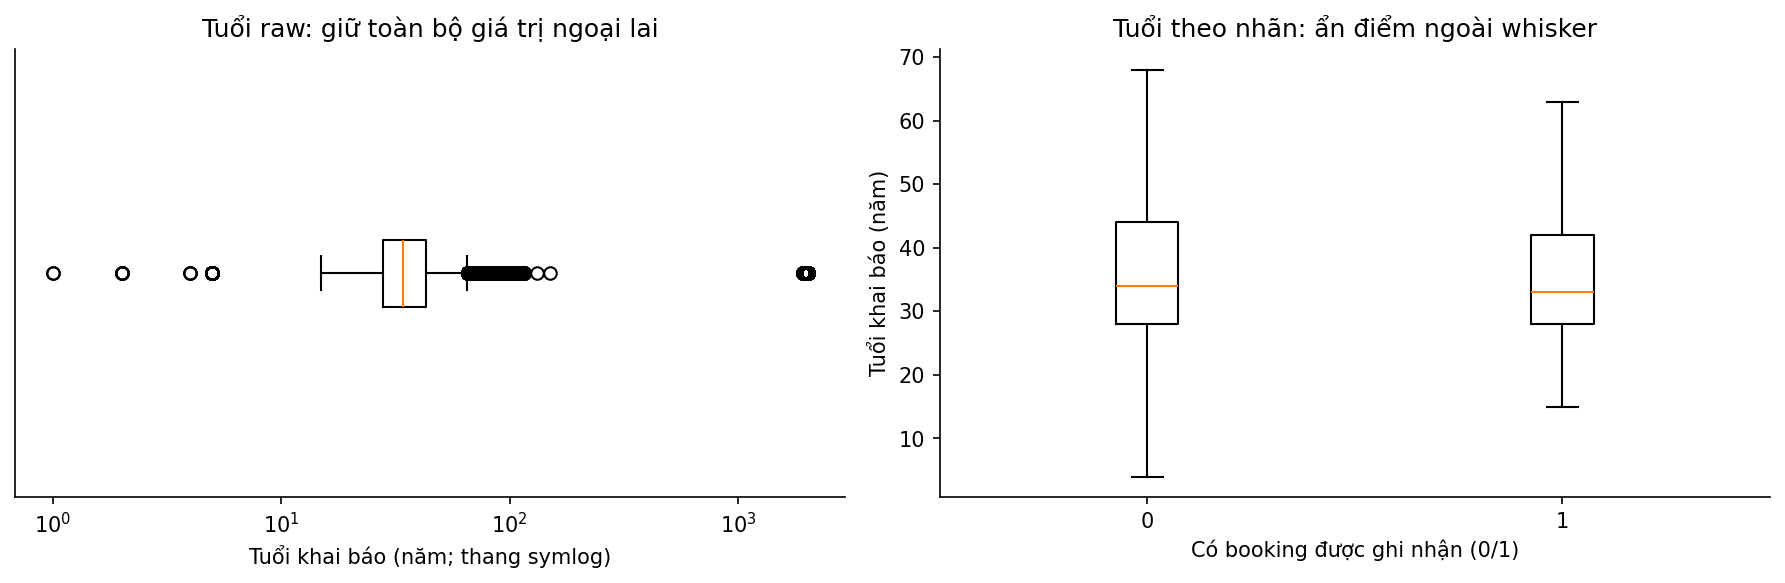

**Quan sát:** theo hàng rào Q1−1.5×IQR và Q3+1.5×IQR, age có 5,594/125,461 giá trị bị gắn cờ (4.46%) trong toàn bộ users train AIRBNB; đây là bất thường thống kê, chưa phải lỗi nhập liệu. Median age theo nhãn: 0=34.00, 1=33.00. Boxplot bên phải ẩn các điểm ngoài whisker để đọc vùng giữa, không xóa chúng khỏi bảng hay raw. Đơn vị xem từ điển; IQR=0 ở biến rời rạc có thể gắn cờ nhiều giá trị thật. Trục x boxplot raw dùng symlog; hàng rào IQR vẫn tính trên giá trị raw, không phải log.

**Phạm vi và cách đọc:** Tuổi không thiếu trong train. Dải ngoại lai là quy tắc mô tả; dữ liệu gốc được giữ nguyên.

### Vai trò dữ liệu trong thiết kế chính

Bảng dưới tóm tắt quyết định theo nhóm cột. Bảng quyết định đầy đủ trong phụ lục chỉ rõ từng cột, điều kiện tại t0 và câu hỏi Q1–Q3 liên quan. Các cột hồ sơ có trạng thái ứng viên có điều kiện, chưa được xác nhận là khả dụng tại t0.

**Tóm tắt quyết định sử dụng dữ liệu**

| Bảng dữ liệu | Quyết định cho thiết kế chính | Số cột |
| --- | --- | --- |
| Hồ sơ người dùng | Dùng đối chiếu và ghép; loại khỏi đầu vào | 1 |
| Hồ sơ người dùng | Dùng kiểm tra và chia thời gian; cân nhắc đầu vào riêng | 2 |
| Hồ sơ người dùng | Loại ngày và cờ thiếu khỏi đầu vào | 1 |
| Hồ sơ người dùng | Ứng viên có điều kiện | 9 |
| Hồ sơ người dùng | Ứng viên có điều kiện; tuổi và cờ thiếu cần cùng được kiểm tra | 1 |
| Hồ sơ người dùng | Ứng viên có điều kiện; không coi là đại lượng liên tục | 1 |
| Hồ sơ người dùng | Chỉ dùng tạo nhãn và đánh giá | 1 |
| Nhật ký hoạt động | Dùng đối chiếu khóa | 1 |
| Nhật ký hoạt động | Loại khỏi đầu vào của thiết kế tại t0 | 5 |
| Thông tin quốc gia | Dùng làm bối cảnh; chưa ghép làm đầu vào | 7 |
| Dân số theo tuổi và giới tính | Dùng làm bối cảnh; chưa ghép làm đầu vào | 5 |

**B4 · Tình trạng hồ sơ tuổi và liên hệ trong năm 2014**

| Số người dùng thiếu tuổi | Tỷ lệ thiếu tuổi (%) | V cờ thiếu tuổi · 2014 | Rank-biserial tuổi 16–100 · 2014 |
| --- | --- | --- | --- |
| 87,990 | 41.2226 | 0.3737 | -0.0049 |

In [6]:
eda.show_section(report, 'quality_main')

## 4. Phân tích đơn biến

### Nhãn, tuổi và phân phối kênh/thiết bị

Có booking được ghi nhận: **88,908/213,451 (41.65%)**. Nhóm NDF chiếm **58.35%**. Bảng điểm đến trình bày hai mẫu số riêng: toàn bộ người dùng và chỉ người có booking; không nhầm tỷ trọng US trong toàn bộ users với tỷ trọng US trong nhóm đã book.

Độ tuổi được trình bày cả raw và cửa sổ [16; 100] để thấy tác động của giá trị cực đoan. Top category có mẫu số là toàn bộ users, kể cả NA. `signup_flow` là mã phân loại; không báo cáo mean của mã như một đặc điểm khách hàng.

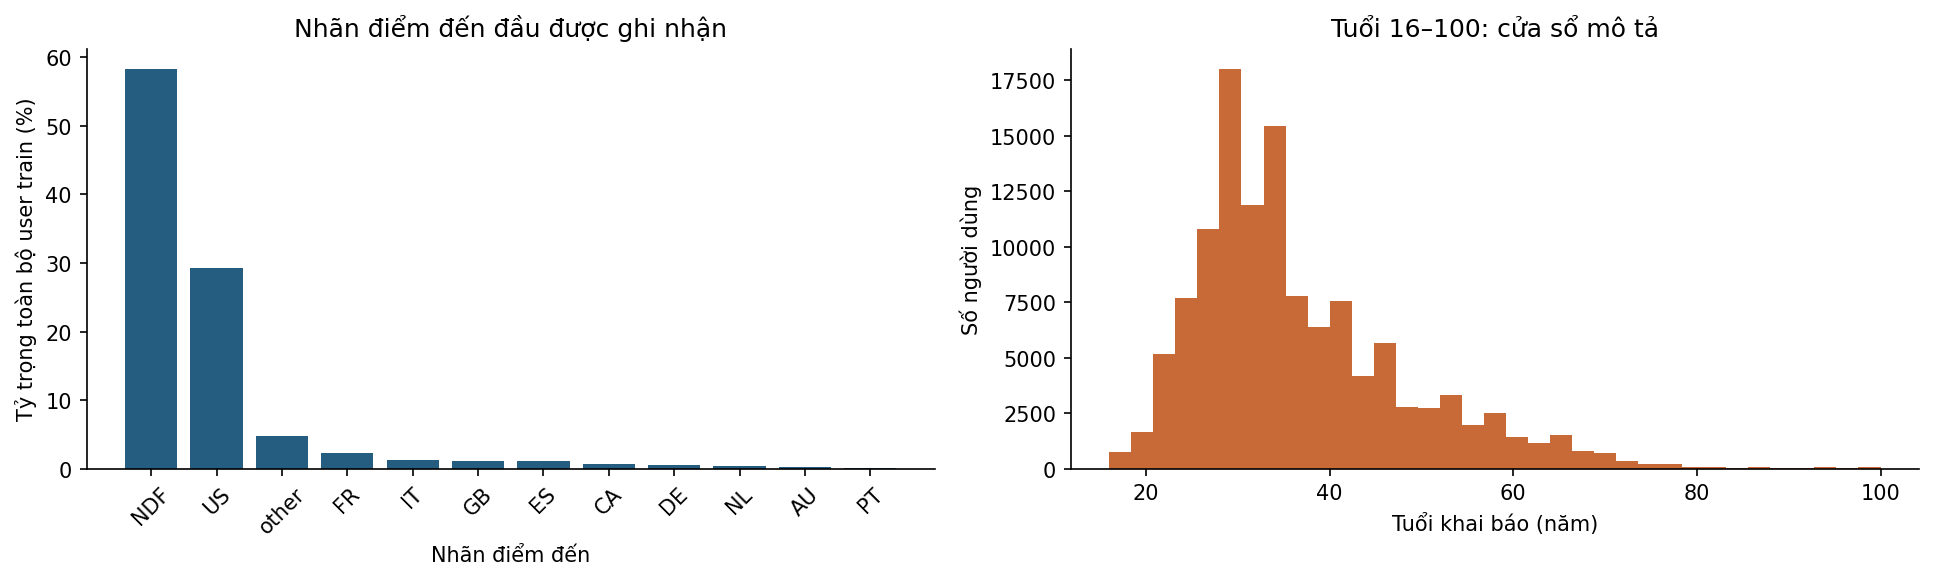

**Quan sát:** NDF chiếm 58.35% toàn users; age thiếu 41.22% và có 2,410 giá trị ngoài dải tham chiếu 16–100. Histogram chỉ vẽ tuổi 16–100, không thay đổi raw hoặc khẳng định mọi tuổi ngoài dải đều sai.

**Phạm vi và cách đọc:** Toàn bộ người dùng train. Biểu đồ tuổi giới hạn hiển thị 16–100; bảng chi tiết giữ tuổi thiếu và ngoài dải.

### Biến phân loại và nhãn

Biểu đồ hiển thị top 8 nhóm theo số lượng; bảng kiểm kê giữ cả các nhóm nhỏ. Nhóm hiếm được báo với ngưỡng mô tả n<100, chưa gộp category.

**Tần suất đầy đủ của Ứng dụng đăng ký**

| Ứng dụng đăng ký | Số người dùng | Số có nhãn y=1 |
| --- | --- | --- |
| Web | 182,717 | 80,021 |
| iOS | 19,019 | 5,511 |
| Moweb | 6,261 | 2,143 |
| Android | 5,454 | 1,233 |

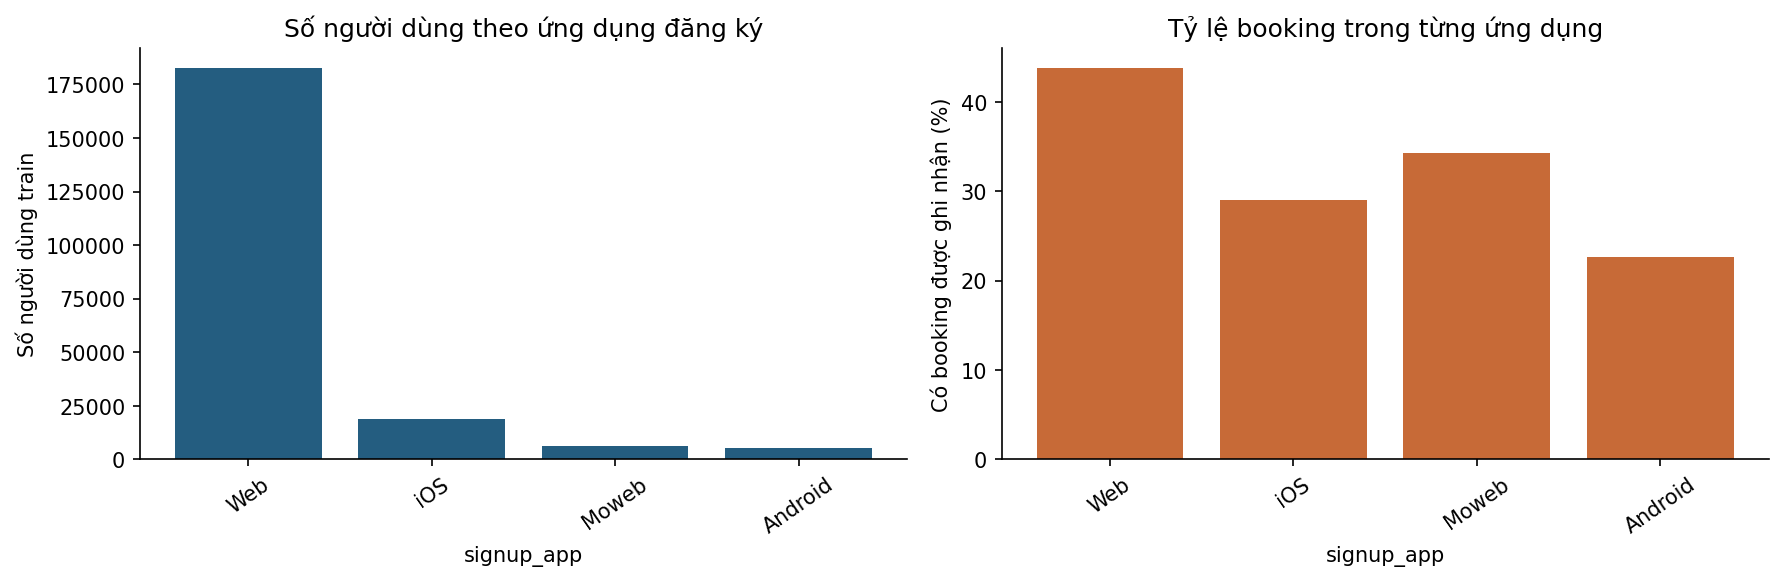

**Quan sát:** signup_app có 4 nhóm (không có NA); 0 nhóm dưới 100 quan sát. Nhóm lớn nhất Web có 182,717 quan sát, tỷ lệ nhãn 1 là 43.80%. Hai trục trả lời số lượng nhóm và tỷ lệ bên trong nhóm, không dùng lẫn mẫu số; phân tầng nhóm đăng ký được trình bày tại phần đa biến.

**Phạm vi và cách đọc:** Toàn bộ người dùng train. Số lượng dùng mẫu số toàn tập; tỷ lệ dùng mẫu số từng ứng dụng.

In [7]:
eda.show_section(report, 'univariate')

## 5. Nhãn, liên hệ đa biến, nhóm đăng ký và Nhật ký hoạt động

### Độ trễ booking và giới hạn định nghĩa nhãn

Độ trễ là số ngày lịch từ ngày tạo tài khoản đến ngày đặt chỗ đầu tiên, tính bằng date_first_booking − date_account_created. Có 88,879 lượt đặt chỗ có độ trễ không âm. Báo cáo thống kê riêng 29 trường hợp có ngày đặt chỗ trước ngày tạo tài khoản để kiểm tra lại định nghĩa thời gian.

**Trong các lượt đặt chỗ có độ trễ hợp lệ, 83.29% xảy ra trong 90 ngày đầu** và 16.71% xảy ra muộn hơn. Vì mẫu số chỉ gồm người đã đặt chỗ, các tỷ lệ này mô tả tốc độ phát sinh đặt chỗ trong nhóm đó. Xác suất đặt chỗ của toàn bộ người dùng cần một mẫu số khác, gồm cả người mang nhãn y=0.

Ngày đặt chỗ muộn nhất là 2015-06-29, cách ngày tạo tài khoản cuối 2014-06-30 là 364 ngày. Độ trễ lớn nhất của từng nhóm năm đăng ký đều bằng 365 ngày. Hai quan sát này ủng hộ mạnh giả thuyết mỗi người được theo dõi tối đa 365 ngày kể từ đăng ký. Chúng chưa trực tiếp xác nhận thời gian theo dõi của từng người mang mã NDF.

Báo cáo dùng giả thuyết theo dõi đủ 365 ngày làm giả định làm việc để xây dựng nhãn nghiên cứu y90 ngay trong EDA. Đây là phân tích có điều kiện và có kịch bản độ nhạy, thay vì chặn toàn bộ nghiên cứu 90 ngày. Xác nhận chính thức cơ chế theo dõi vẫn là điều kiện trước khi suy rộng hoặc triển khai.

Nhãn y90 bằng 1 nếu ngày đặt chỗ đầu tiên cách ngày tạo tài khoản từ 0 đến 90 ngày, gồm cả hai đầu. Nhãn bằng 0 cho lượt đặt chỗ muộn hơn 90 ngày và cho NDF dưới giả định theo dõi đủ 365 ngày. Các ngoại lệ ngày đặt chỗ âm để trạng thái chưa gán. Ngày 0 được giữ theo độ phân giải ngày của CSV; Q1/Q2 vẫn cần làm rõ thứ tự trong ngày.

**B6 · Phân phối độ trễ: mẫu số và ngoại lệ**

| Số có nhãn y=1 | Số độ trễ không âm | Số độ trễ âm | Ngày đặt chỗ thiếu hoặc không đọc được | Trung vị (ngày) | Phân vị 75% (ngày) | Phân vị 90% (ngày) | Phân vị 95% (ngày) | Lớn nhất (ngày) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 88,908 | 88,879 | 29 | 0 | 3 | 29 | 189 | 278 | 365 |

**B2 · Mức bao phủ các thời hạn trên lượt đặt chỗ đã ghi nhận**

| Thời hạn (ngày) | Số đặt chỗ trong thời hạn | Mẫu số · độ trễ hợp lệ | Trong số độ trễ hợp lệ (%) | Trong số người đã đặt chỗ (%) |
| --- | --- | --- | --- | --- |
| 7 | 55,366 | 88,879 | 62.2937 | 62.2734 |
| 30 | 66,950 | 88,879 | 75.3271 | 75.3026 |
| 60 | 71,333 | 88,879 | 80.2586 | 80.2324 |
| 90 | 74,027 | 88,879 | 83.2896 | 83.2625 |
| 180 | 79,524 | 88,879 | 89.4745 | 89.4453 |
| 365 | 88,879 | 88,879 | 100 | 99.9674 |

... (6 outputs left out)

**Quy tắc gán nhãn 90 ngày và số lượng**

| Trường hợp | Số người dùng | Nhãn y90 | Căn cứ |
| --- | --- | --- | --- |
| Đã đặt chỗ, độ trễ từ 0 đến 90 ngày | 74,027 | 1 | Đã quan sát lượt đặt chỗ trong thời hạn |
| Đã đặt chỗ, độ trễ lớn hơn 90 ngày | 14,852 | 0 | Lượt đặt chỗ đầu tiên xảy ra sau thời hạn |
| NDF | 124,543 | 0 có điều kiện | Chỉ gán âm khi chấp nhận giả định theo dõi đủ 365 ngày |
| Ngày đặt chỗ âm hoặc không xác định | 29 | Chưa gán | Loại khỏi mẫu nghiên cứu 90 ngày cho đến khi xác minh |

**Độ nhạy khi không giả định theo dõi cho NDF**

| Kịch bản | Dương tính | Âm tính xác định trong kịch bản | Chưa xác định | Mẫu gán được nhãn |
| --- | --- | --- | --- | --- |
| Giả định mỗi người được theo dõi 365 ngày | 74,027 | 139,395 | 29 | 213,422 |
| Chỉ dùng bằng chứng lượt đặt chỗ đã ghi nhận | 74,027 | 14,852 | 124,572 | 88,879 |

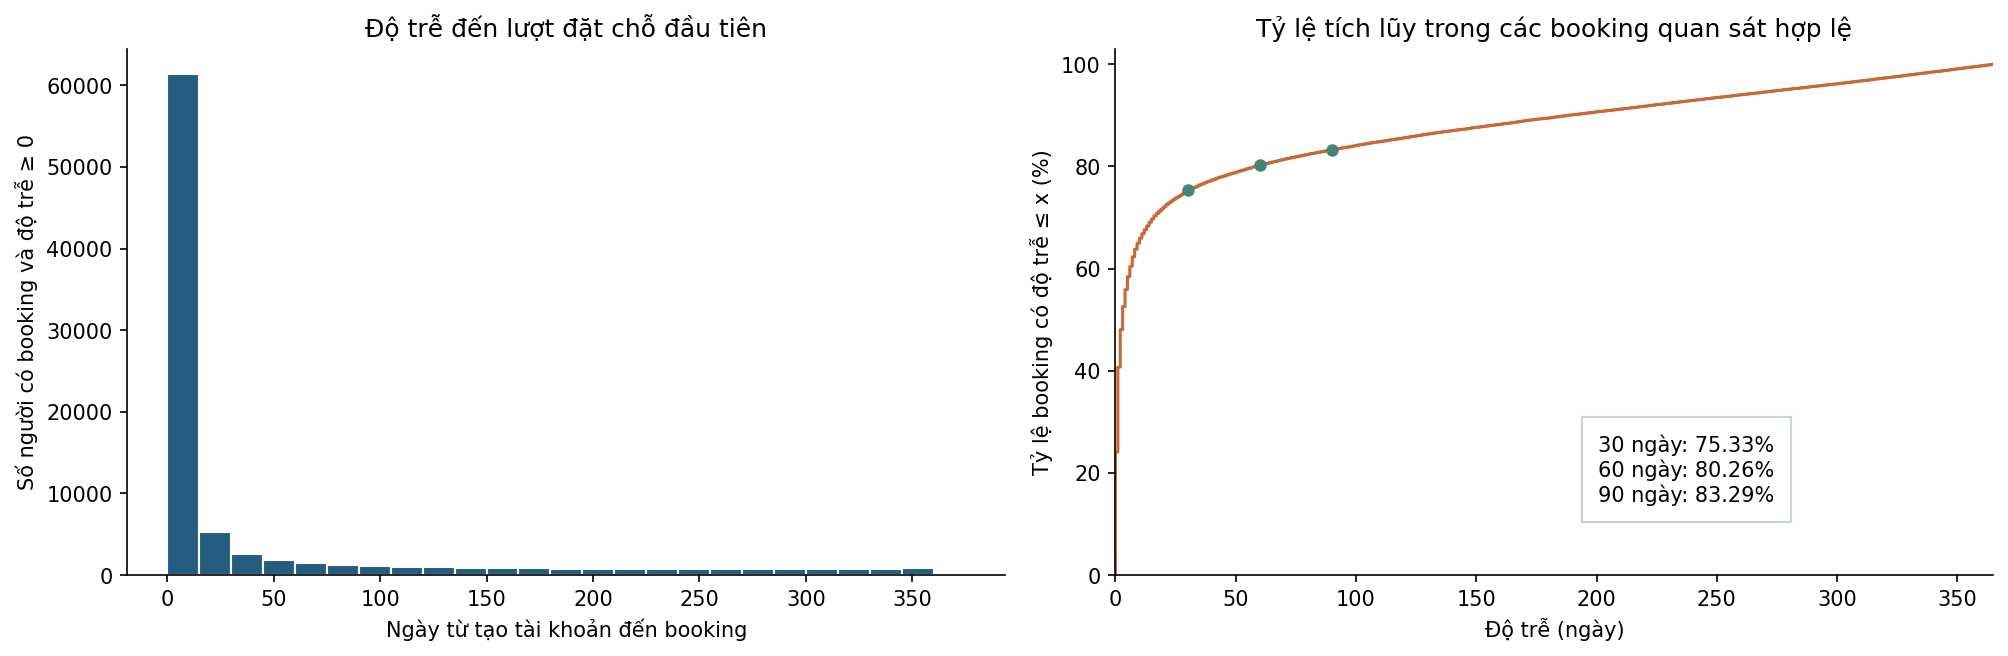

**Quan sát:** trong 88,879 lượt đặt chỗ có độ trễ không âm, 75.33% xảy ra trong 30 ngày, 80.26% trong 60 ngày và 83.29% trong 90 ngày. Phần tăng thêm từ ngày 30 đến ngày 90 cho thấy lợi ích về mức bao phủ khi kéo dài thời hạn. Mẫu số chỉ gồm các lượt đặt chỗ có độ trễ hợp lệ. Bảng ngoại lệ thống kê riêng 29 trường hợp độ trễ âm.

**Phạm vi và cách đọc:** Người đã đặt chỗ và có độ trễ không âm. Các tỷ lệ không đại diện cho toàn bộ người dùng.

### Độ mạnh liên hệ với nhãn y trên toàn bộ biến ứng viên

Phân tích xem xét 13 cột ứng viên và bổ sung góc nhìn về tình trạng thiếu tuổi, tổng cộng 14 phép so sánh. Cramér V đo độ mạnh liên hệ giữa biến phân loại và nhãn y trên thang 0–1. Hệ số của toàn bộ train được đối chiếu với kết quả riêng năm 2014 để kiểm tra ảnh hưởng của thành phần năm đăng ký.

Giới tính khai báo có V=0.207 trên toàn kỳ và 0.251 trong năm 2014. Ứng dụng đăng ký có V tương ứng 0.109 và 0.156, thể hiện liên hệ yếu hơn trong cả hai phạm vi. Đây là mô tả từng biến, không phải điểm chất lượng mô hình. Tuổi trong dải 16–100 dùng rank-biserial trên thang −1 đến 1. Giá trị -0.005 trong năm 2014 cho thấy khác biệt thứ hạng tuổi giữa hai nhóm nhãn rất nhỏ.

Công thức, giả định kiểm định và điều chỉnh nhiều phép so sánh nằm ở mục Tái lập và kiểm soát phạm vi. Báo cáo chưa đưa AUC vì chưa huấn luyện mô hình. [Phương pháp Cramér V](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html) và [Mann–Whitney](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html) được đối chiếu từ tài liệu SciPy.

Cramér V của giới tính và cờ thiếu tuổi không được xem là hai bằng chứng dự báo độc lập. Phần độ đầy đủ hồ sơ bên dưới định lượng mức chồng lặp và tách chênh lệch ứng dụng trong từng nhóm hồ sơ.

**B3 · Các liên hệ chính cần kiểm tra**

| Biến | Thước đo | Liên hệ · toàn kỳ | Liên hệ · năm 2014 |
| --- | --- | --- | --- |
| Giới tính khai báo | Cramér V | 0.2073 | 0.2507 |
| Cách đăng ký | Cramér V | 0.0359 | 0.0371 |
| Ứng dụng đăng ký | Cramér V | 0.1095 | 0.1559 |
| Tình trạng thiếu tuổi | Cramér V | 0.3142 | 0.3737 |
| Tuổi trong dải 16–100 | Rank-biserial | -0.0324 | -0.0049 |

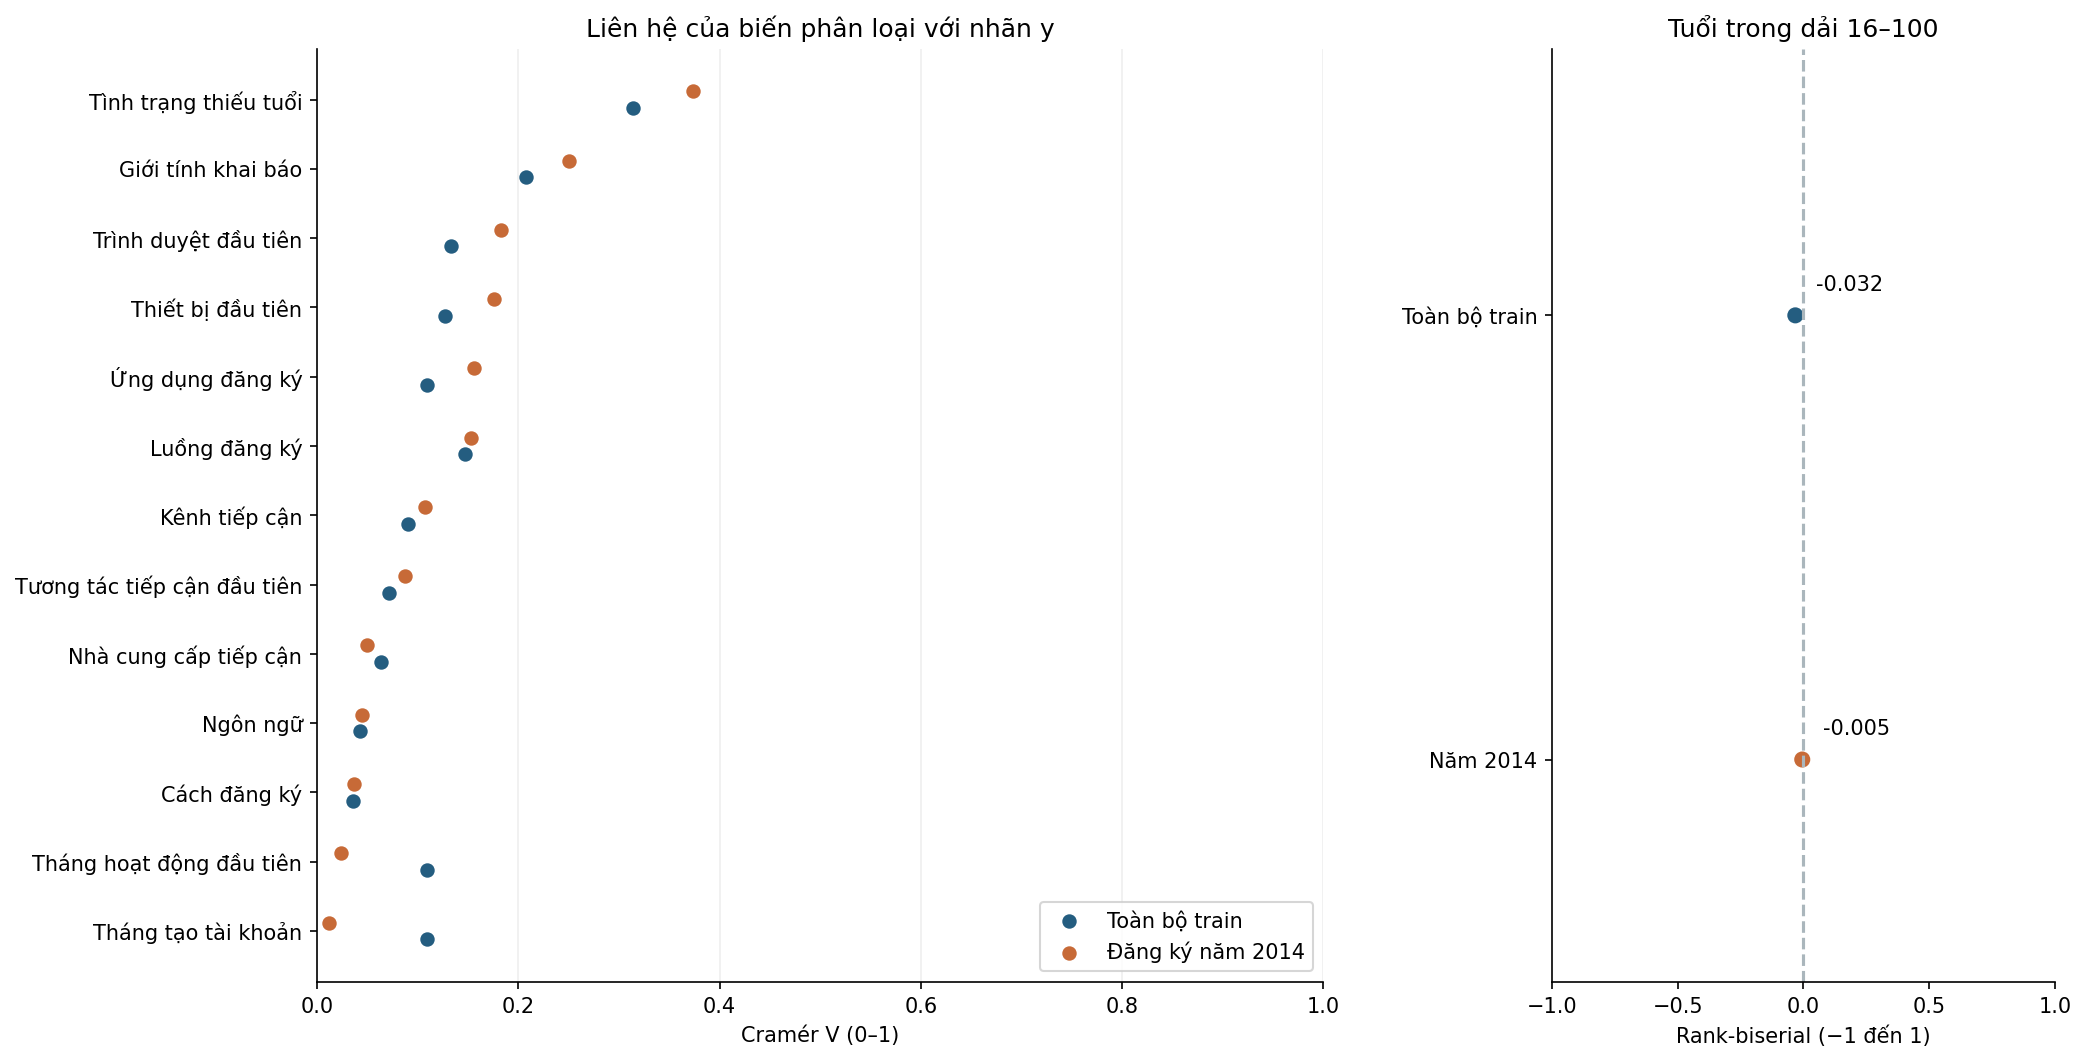

**Quan sát:** tình trạng thiếu tuổi có V lớn nhất trong các biến phân loại được khảo sát. Liên hệ của các mốc theo tháng giảm khi chỉ xét năm 2014. Tuổi trong dải 16–100 có rank-biserial=-0.005 trong năm 2014, gần 0.

**Phạm vi và cách đọc:** V tính trên toàn bộ người dùng trong từng phạm vi, gồm giá trị thiếu như một nhóm. Rank-biserial chỉ tính trên tuổi 16–100 và được đặt trên trục riêng. Hai thước đo không dùng chung ngưỡng so sánh. Liên hệ của cờ thiếu cần được kiểm tra về thời điểm có sẵn tại t0.

### Độ đầy đủ hồ sơ và chênh lệch ứng dụng sau phân tầng

Trong nhóm đăng ký năm 2014, tỷ lệ có nhãn y=1 của FEMALE và MALE gần bằng nhau, lần lượt 50.84% và 50.95%. Nhóm không rõ giới tính chỉ đạt 26.54%. Vì vậy, liên hệ biên của cột giới tính chủ yếu phản ánh sự khác nhau giữa hồ sơ có và thiếu thông tin, không nên trình bày như một hiệu ứng riêng của giới tính.

Cờ thiếu tuổi và cờ không rõ giới tính có Cramér V=0.783. Đây là liên hệ mạnh giữa hai chỉ báo đầu vào, cho thấy tín hiệu chồng lặp. Nó không tự chứng minh cộng tuyến hoàn toàn hoặc quan hệ nhân quả. Cần kiểm tra loại từng cờ trong cùng thiết kế Logistic Regression và CatBoost.

Bảng và hình dưới tách đồng thời năm đăng ký, tình trạng thiếu tuổi và tình trạng không rõ giới tính trước khi so sánh ứng dụng. Chúng báo cả nhãn y hiện có và nhãn y90 có điều kiện. Các khoảng Wilson dành cho tỷ lệ y90 trong từng ô, với n<100 được đánh dấu. Giá trị tuổi và các cờ thiếu vẫn phải được xác minh là có sẵn tại t0.

**B10 · Tín hiệu độ đầy đủ hồ sơ · năm 2014**

| Năm đăng ký | FEMALE · nhãn y (%) | MALE · nhãn y (%) | Không rõ giới tính · nhãn y (%) | Có tuổi · nhãn y (%) | Thiếu tuổi · nhãn y (%) | V giữa hai cờ thiếu hồ sơ |
| --- | --- | --- | --- | --- | --- | --- |
| 2014 | 50.838 | 50.9549 | 26.5401 | 54.5444 | 18.0087 | 0.7831 |

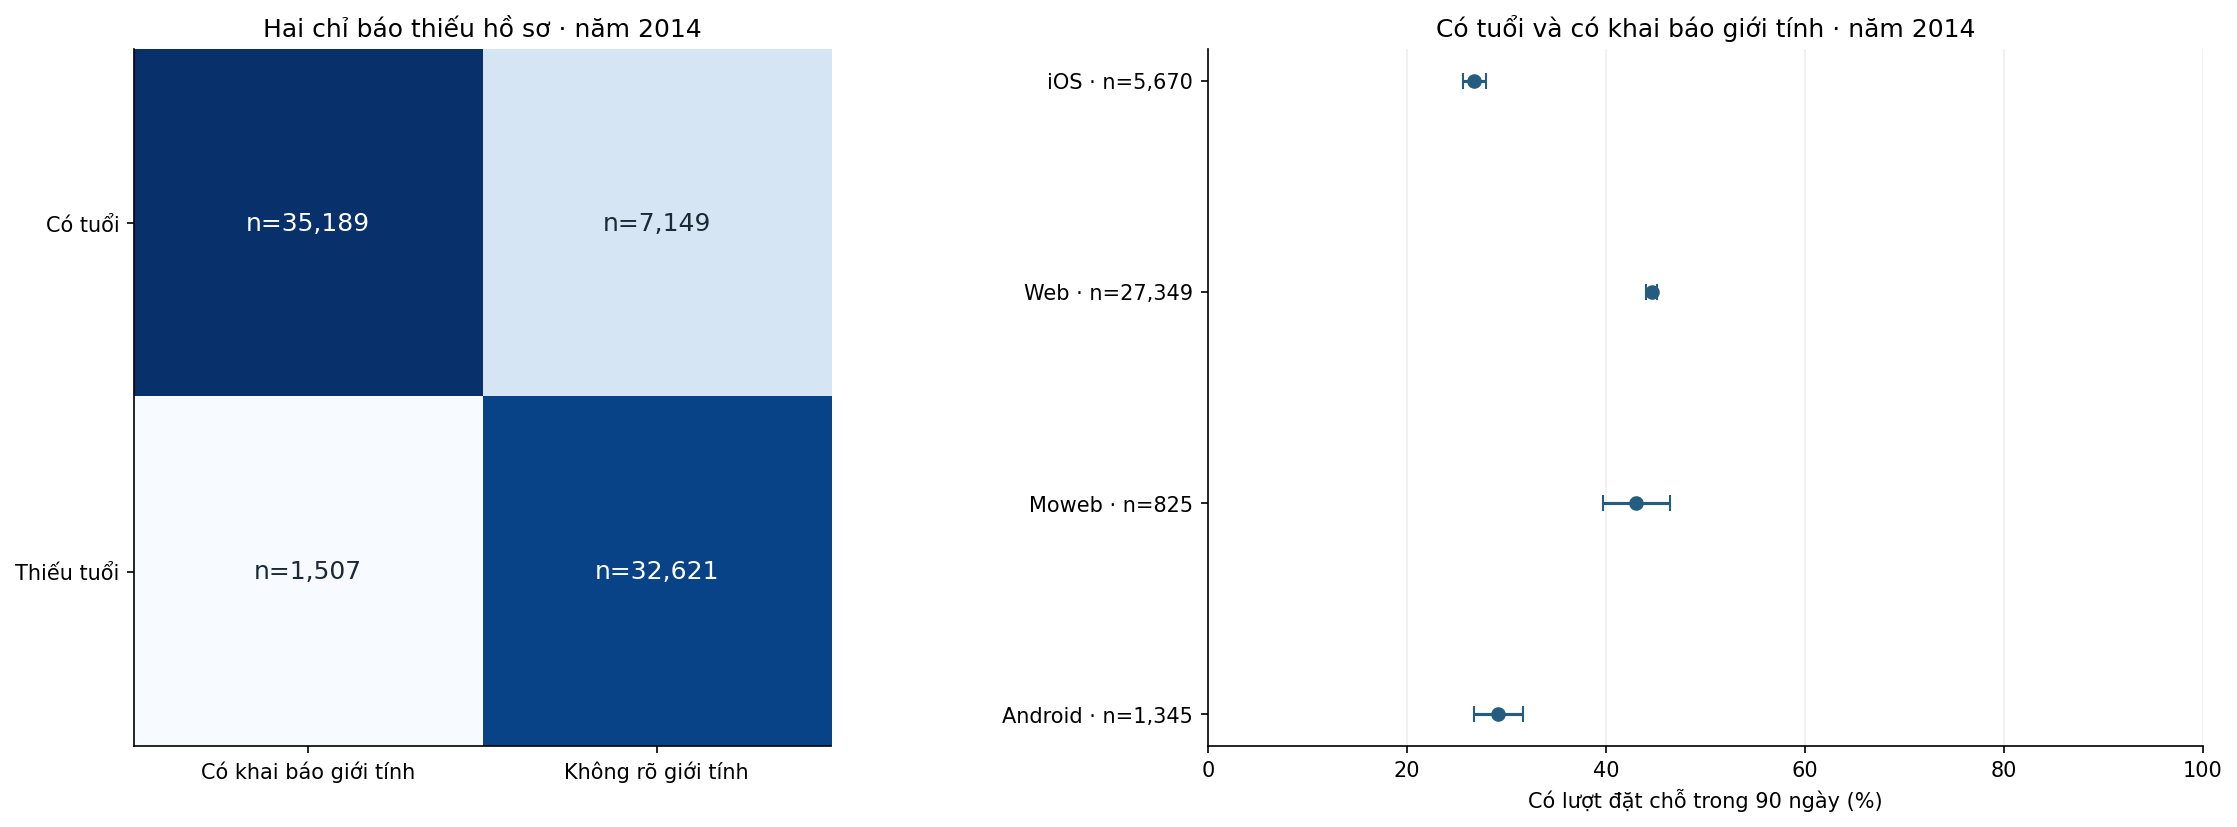

**Quan sát:** thiếu tuổi thường đi cùng tình trạng không rõ giới tính. Chênh lệch ứng dụng vẫn xuất hiện trong nhóm có đủ hai thông tin này.

**Phạm vi và cách đọc:** bên trái là số người dùng trong bốn ô hồ sơ. Bên phải là nhãn y90 dưới giả định theo dõi 365 ngày, chỉ trong nhóm có tuổi và có khai báo giới tính, với khoảng Wilson 95%. Bảng B11 giữ cả bốn mức đầy đủ hồ sơ. Đây là phân tầng mô tả, chưa kiểm soát mọi khác biệt và chưa xác nhận thông tin có sẵn tại t0.

### Tỷ lệ đặt chỗ và độ bất định theo các nhóm chính

Ba nhóm đặc điểm dưới đây được so sánh trên cùng quần thể đăng ký năm 2014. Mỗi điểm là tỷ lệ có nhãn y=1 trong nhóm, thanh ngang là khoảng Wilson 95%. Bảng gom các nhóm vào cùng một cấu trúc để đọc đồng thời cỡ mẫu, tỷ lệ và độ bất định. Bảng toàn bộ train và các đặc điểm khác nằm ở phụ lục.

**Tỷ lệ đặt chỗ theo nhóm · cùng năm đăng ký 2014**

| Đặc điểm | Nhóm | Số người dùng | Số có nhãn y=1 | Tỷ lệ đặt chỗ (%) | Cận dưới 95% (%) | Cận trên 95% (%) |
| --- | --- | --- | --- | --- | --- | --- |
| Giới tính khai báo | -unknown- | 39,770 | 10,555 | 26.5401 | 26.1084 | 26.9763 |
| Giới tính khai báo | FEMALE | 19,450 | 9,888 | 50.838 | 50.1354 | 51.5404 |
| Giới tính khai báo | MALE | 17,174 | 8,751 | 50.9549 | 50.2071 | 51.7023 |
| Giới tính khai báo | OTHER | 72 | 45 | 62.5 | 50.9529 | 72.7808 |
| Ứng dụng đăng ký | Android | 3,808 | 832 | 21.8487 | 20.565 | 23.1892 |
| Ứng dụng đăng ký | Moweb | 2,617 | 778 | 29.7287 | 28.0083 | 31.5085 |
| Ứng dụng đăng ký | Web | 57,542 | 24,475 | 42.5341 | 42.1307 | 42.9386 |
| Ứng dụng đăng ký | iOS | 12,499 | 3,154 | 25.234 | 24.4802 | 26.003 |
| Tình trạng thiếu tuổi | Có tuổi | 42,338 | 23,093 | 54.5444 | 54.0697 | 55.0182 |
| Tình trạng thiếu tuổi | Thiếu tuổi | 34,128 | 6,146 | 18.0087 | 17.6046 | 18.4199 |

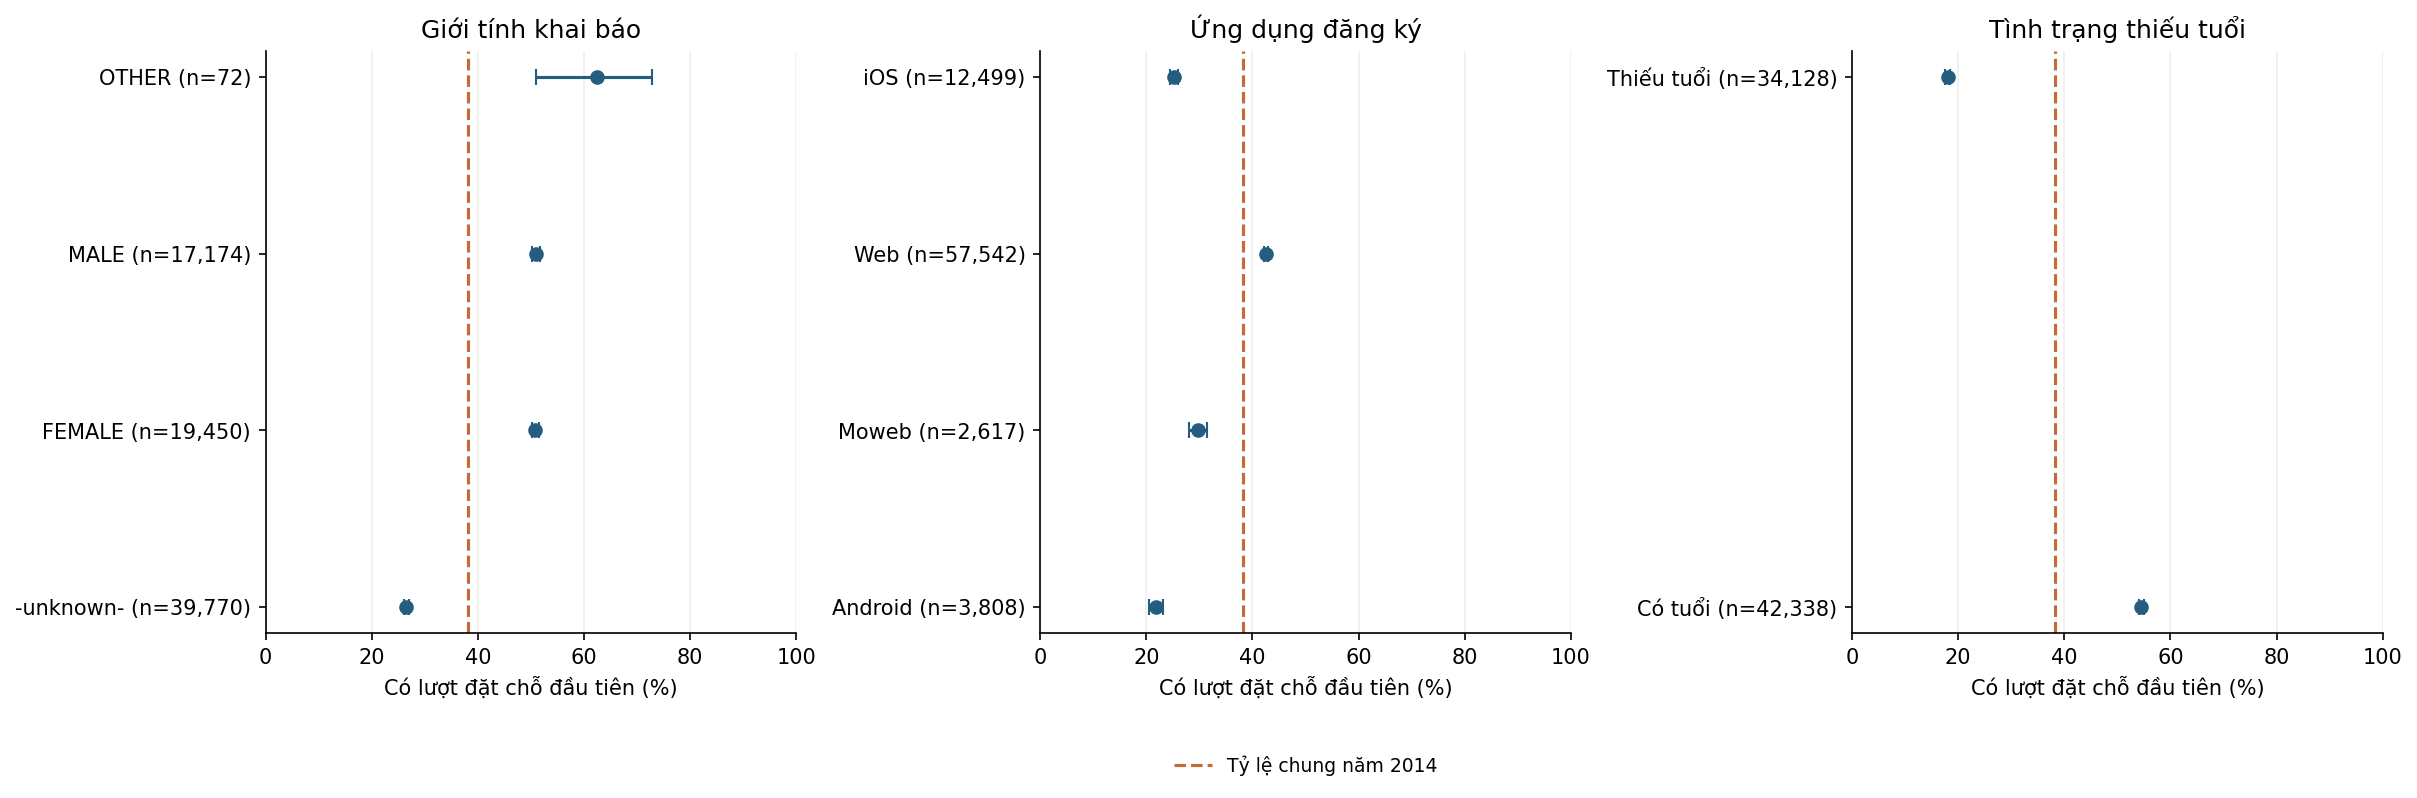

**Quan sát:** đường đứt đánh dấu tỷ lệ chung 38.24% của người đăng ký năm 2014. Khoảng rộng ở các nhóm ít người cho thấy tỷ lệ ước lượng kém chính xác hơn.

**Phạm vi và cách đọc:** mẫu số của mỗi điểm là số người trong nhóm, được ghi cạnh tên. Khoảng Wilson 95% giả định người dùng độc lập. Mức chồng lấp khoảng tin cậy không thay thế kiểm định chênh lệch. Tuổi và tình trạng thiếu tuổi chỉ là ứng viên đầu vào sau khi xác minh tại t0.

### Tách thành phần nhóm đăng ký khỏi chênh lệch app, Giới tính khai báo và kênh

Mỗi cột trong bảng tương ứng với một năm tạo tài khoản. Đọc theo cột giúp so sánh ứng dụng, giới tính hoặc kênh tiếp cận trong cùng nhóm đăng ký. Một số ứng dụng chỉ xuất hiện ở các năm sau, nên so sánh toàn kỳ có thể chịu ảnh hưởng của thành phần năm.

Việc tách theo năm giúp kiểm tra một phần ảnh hưởng này. Khác biệt theo tháng hoặc các đặc điểm khác vẫn cần được xem xét khi xây dựng mô hình. Phụ lục cung cấp khoảng Wilson 95% cho từng ô để đọc cùng số người dùng.

**Ứng dụng đăng ký × năm signup: tỷ lệ và n**

| Ứng dụng đăng ký | 2010 | 2011 | 2012 | 2013 | 2014 |
| --- | --- | --- | --- | --- | --- |
| Android | Không có user | Không có user | 64.00% (n=25) | 23.75% (n=1,621) | 21.85% (n=3,808) |
| Moweb | Không có user | Không có user | 41.61% (n=560) | 36.71% (n=3,084) | 29.73% (n=2,617) |
| Web | 57.50% (n=2,788) | 54.63% (n=11,775) | 45.02% (n=38,184) | 41.86% (n=72,428) | 42.53% (n=57,542) |
| iOS | Không có user | Không có user | 44.44% (n=693) | 35.16% (n=5,827) | 25.23% (n=12,499) |

**Giới tính khai báo × năm signup: tỷ lệ và n**

| Giới tính khai báo | 2010 | 2011 | 2012 | 2013 | 2014 |
| --- | --- | --- | --- | --- | --- |
| -unknown- | 53.68% (n=1,509) | 54.45% (n=4,617) | 35.75% (n=10,993) | 28.89% (n=38,799) | 26.54% (n=39,770) |
| FEMALE | 61.89% (n=732) | 55.51% (n=3,693) | 48.52% (n=15,535) | 51.05% (n=23,631) | 50.84% (n=19,450) |
| MALE | 62.02% (n=545) | 53.74% (n=3,439) | 48.50% (n=12,846) | 51.64% (n=20,436) | 50.95% (n=17,174) |
| OTHER | 100.00% (n=2) | 80.77% (n=26) | 57.95% (n=88) | 60.64% (n=94) | 62.50% (n=72) |

**Kênh tiếp cận × năm signup: tỷ lệ và n**

| Kênh tiếp cận | 2010 | 2011 | 2012 | 2013 | 2014 |
| --- | --- | --- | --- | --- | --- |
| api | Không có user | 100.00% (n=1) | 45.73% (n=1,813) | 33.76% (n=3,504) | 27.10% (n=2,849) |
| content | 49.47% (n=95) | 37.50% (n=296) | 15.97% (n=432) | 10.05% (n=1,482) | 11.08% (n=1,643) |
| direct | 61.98% (n=1,310) | 56.32% (n=6,578) | 47.71% (n=25,114) | 43.03% (n=55,522) | 38.63% (n=49,203) |
| other | 52.62% (n=650) | 52.35% (n=1,593) | 39.05% (n=3,201) | 32.43% (n=2,661) | 36.33% (n=856) |
| remarketing | Không có user | 50.00% (n=94) | 44.96% (n=129) | 28.18% (n=181) | 30.64% (n=692) |
| sem-brand | 59.46% (n=37) | 54.95% (n=777) | 41.97% (n=2,783) | 41.28% (n=9,755) | 42.94% (n=12,693) |
| sem-non-brand | 49.11% (n=395) | 52.06% (n=1,800) | 38.75% (n=4,872) | 35.02% (n=6,604) | 35.14% (n=5,173) |
| seo | 61.79% (n=301) | 58.33% (n=636) | 45.26% (n=1,118) | 43.25% (n=3,251) | 44.27% (n=3,357) |

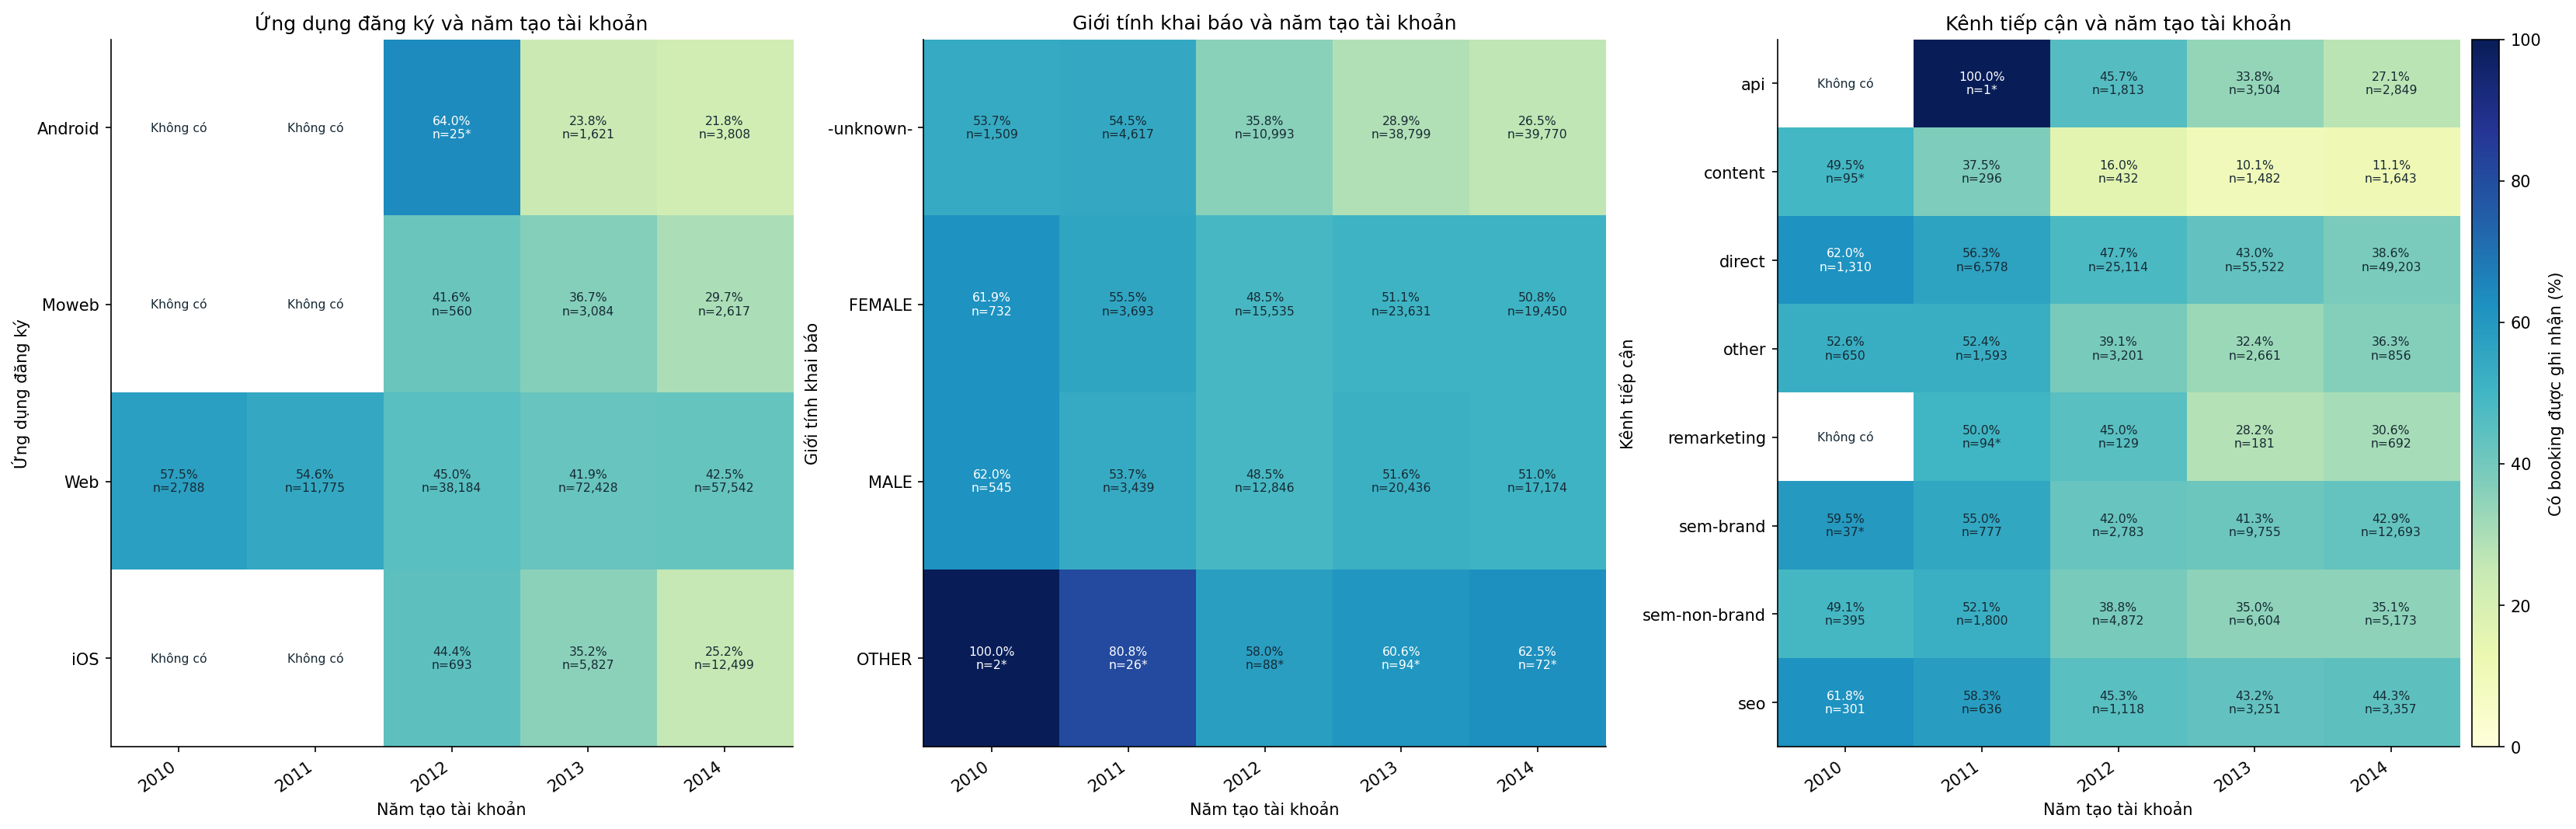

**Quan sát:** trong năm 2014, tỷ lệ đặt chỗ của Web là 42.53%, iOS là 25.23% và Android là 21.85%. Chênh lệch giữa các ứng dụng vẫn xuất hiện khi so sánh trong cùng năm. Nhóm FEMALE có tỷ lệ 50.84%, so với 26.54% ở nhóm giới tính unknown. Nhóm OTHER chỉ có 72 người nên cần đọc cùng khoảng Wilson trong phụ lục. Dấu * đánh dấu ô có n<100.

**Phạm vi và cách đọc:** Người dùng train, tách theo năm đăng ký. Ô có n<100 được đánh dấu; khoảng Wilson ở phụ lục.

### Tỷ lệ đặt chỗ theo các nhóm kết hợp trong năm 2014

Hai biểu đồ kết hợp ứng dụng đăng ký với kênh tiếp cận, và tình trạng thiếu tuổi với giới tính khai báo. Cách nhìn này giúp xác định những nhóm cần kiểm tra thêm trong mô hình. Màu biểu diễn tỷ lệ đặt chỗ, còn n cho biết số người dùng trong ô. Dấu * đánh dấu ô có dưới 100 người. Các nhóm và cờ thiếu được tính tạm để lập bảng EDA.

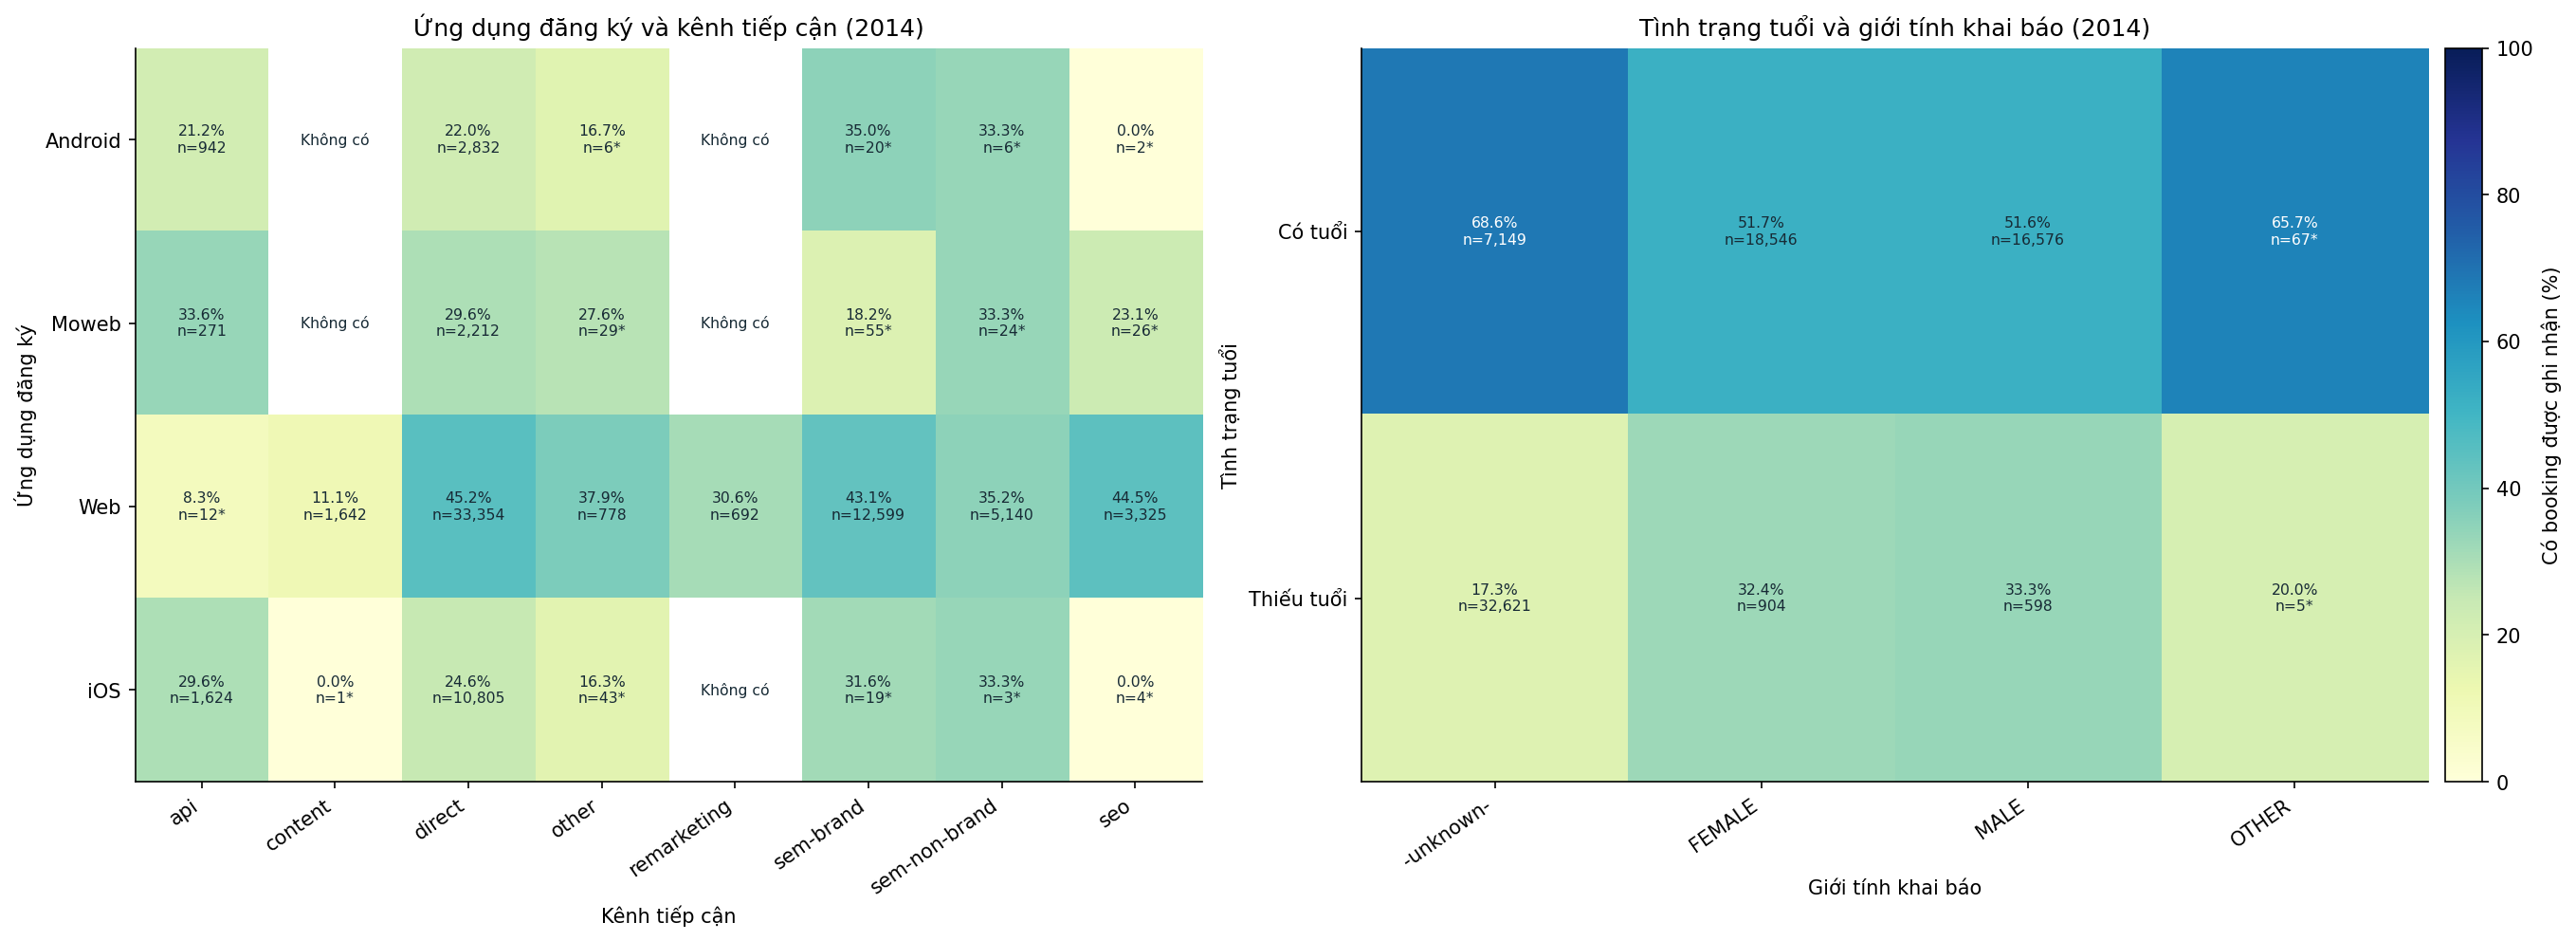

**Quan sát:** với người dùng Web năm 2014, nhóm direct có tỷ lệ đặt chỗ 45.18% (n=33,354). Nhóm content có tỷ lệ 11.08% (n=1,642). Trong nhóm FEMALE cùng năm, tỷ lệ của người có tuổi là 51.74%, so với 32.41% ở người thiếu tuổi. Các chênh lệch trong cùng năm là cơ sở để kiểm tra giá trị của những nhóm kết hợp khi huấn luyện. Dấu * đánh dấu ô có n<100.

**Phạm vi và cách đọc:** Người đăng ký năm 2014. Mẫu số là người trong từng ô kết hợp; dấu * là n<100.

### Sessions: so sánh cùng nhóm đăng ký và rà soát thông tin giao dịch

Phân tích đã quét toàn bộ 10,567,737 sự kiện. Trong nhóm đăng ký năm 2014, **73,815/76,466 người dùng train có sessions (96.53%)**. Tỷ lệ tương ứng ở test là **99.31%**, cao hơn 2.78 điểm phần trăm. Tỷ lệ trên toàn bộ train chỉ là 34.58% vì nhóm đăng ký năm 2010–2013 không có nhật ký trong dữ liệu hiện có. Vì vậy, cần so sánh độ phủ trong cùng năm đăng ký.

Nghiên cứu riêng sessions có phạm vi phù hợp là 76,466 người dùng train đăng ký năm 2014. Tuy nhiên, thiết kế dự đoán tại t0 cần biết sự kiện nào đã xảy ra trước thời điểm đó. Vì sessions thiếu thời điểm sự kiện, thiết kế chính loại nguồn này khỏi đầu vào cho đến khi xác minh được khoảng thời gian ghi nhật ký.

Bảng dưới so sánh người có và không có sessions trong năm 2014. Bảng số sự kiện giữ cả người không có nhật ký và gán event_n=0 khi tính thống kê. Cột secs_elapsed là thời lượng, nên không xác định được thời điểm hoặc thứ tự hành động.

Để rà soát rủi ro rò rỉ, phân tích chọn tên hành động liên quan giao dịch hoặc xác minh bằng biểu thức **(?:^|_)(?:book[a-z]*|reserv[a-z]*|pay[a-z]*|checkout|receipt|itinerar[a-z]*|confirm[a-z]*|request[a-z]*|billing)(?:_|$)**. Quy tắc tên được đặt trước khi xem liên hệ với nhãn y và khớp các thành phần tên phân cách bằng dấu gạch dưới. Bảng giữ đầy đủ action_type để đối chiếu. Mỗi người chỉ được đếm một lần cho mỗi tên hành động sau khi gộp toàn bộ dữ liệu.

**Kết quả rà soát:** trong những người có hành động receipt, 101/102 người có nhãn y=1 (99.02%). Với requested, con số tương ứng là 6,192/7,090 (87.33%). Các tỷ lệ cao cho thấy cần xác minh liệu nhật ký có chứa bước gần hoặc sau thời điểm đặt chỗ. Tên hành động có thể bao gồm yêu cầu thất bại, xác minh tài khoản hoặc chuẩn bị thanh toán, nên cần dữ liệu thời gian và mô tả nghiệp vụ để xác định ý nghĩa.

Hai cột pct_booked_users_with_action và pct_ndf_users_with_action có mẫu số là số người có sessions trong từng nhóm y=1 và y=0. Cột booking_rate_pct có mẫu số là số người có hành động đó. Các cột trả lời hai câu hỏi khác nhau: hành động phổ biến đến đâu trong mỗi nhóm nhãn, và tỷ lệ đặt chỗ của người có hành động là bao nhiêu.

**B5 · Độ phủ nhật ký và tỷ lệ đặt chỗ**

| Phạm vi | Số người dùng | Số có nhật ký | Độ phủ (%) | Chênh với train 2014 (điểm %) | Tỷ lệ đặt chỗ · có nhật ký (%) | Tỷ lệ đặt chỗ · thiếu nhật ký (%) |
| --- | --- | --- | --- | --- | --- | --- |
| Train toàn kỳ | 213,451 | 73,815 | 34.5817 | — | — | — |
| Train năm 2014 | 76,466 | 73,815 | 96.5331 | 0 | 38.9812 | 17.5406 |
| Test năm 2014 | 62,096 | 61,668 | 99.3107 | 2.7776 | — | — |

**Độ phủ năm account train**

... (3 outputs left out)

**Số sự kiện/user theo có log và nhãn — chỉ nhóm đăng ký 2014**

| Có nhật ký hoạt động | Nhãn y | Số người dùng | mean events | median events | p90 events | p99 events | max events |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0 | 2,186 | 0 | 0 | 0 | 0 | 0 |
| 0 | 1 | 465 | 0 | 0 | 0 | 0 | 0 |
| 1 | 0 | 45,041 | 67.8873 | 33 | 167 | 485.6 | 2,323 |
| 1 | 1 | 28,774 | 86.1975 | 45 | 207 | 592 | 2,644 |

**Presence tên ứng viên giao dịch/xác minh × nhãn, trong user 2014 có log**

| field | Giá trị | users with action | Số có nhãn y=1 | ndf users | booking rate pct | Cận dưới 95% (%) | Cận trên 95% (%) | pct booked users with action | pct ndf users with action | Nhóm dưới 100 người |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| action | confirm_email | 30,986 | 15,611 | 15,375 | 50.3808 | 49.8241 | 50.9374 | 54.2538 | 34.1356 | 0 |
| action | requested | 7,090 | 6,192 | 898 | 87.3343 | 86.5398 | 88.0883 | 21.5194 | 1.9937 | 0 |
| action | payment_instruments | 3,804 | 1,395 | 2,409 | 36.6719 | 35.1547 | 38.2161 | 4.8481 | 5.3485 | 0 |
| action | request_new_confirm_email | 2,619 | 1,754 | 865 | 66.9721 | 65.1472 | 68.7473 | 6.0958 | 1.9205 | 0 |
| action | payment_methods | 1,901 | 859 | 1,042 | 45.1867 | 42.9615 | 47.4314 | 2.9853 | 2.3134 | 0 |
| action | apply_reservation | 1,344 | 889 | 455 | 66.1458 | 63.5731 | 68.6265 | 3.0896 | 1.0102 | 0 |
| action | payout_preferences | 933 | 386 | 547 | 41.3719 | 38.2534 | 44.5612 | 1.3415 | 1.2144 | 0 |
| action | tos_confirm | 899 | 287 | 612 | 31.9244 | 28.9594 | 35.0431 | 0.9974 | 1.3588 | 0 |
| action | recent_reservations | 796 | 365 | 431 | 45.8543 | 42.421 | 49.3274 | 1.2685 | 0.9569 | 0 |
| action | pay | 737 | 563 | 174 | 76.3908 | 73.1928 | 79.3151 | 1.9566 | 0.3863 | 0 |
| action | itinerary | 482 | 412 | 70 | 85.4772 | 82.0512 | 88.3421 | 1.4318 | 0.1554 | 0 |
| action | ajax_payout_options_by_country | 362 | 103 | 259 | 28.453 | 24.0504 | 33.3082 | 0.358 | 0.575 | 0 |
| action | ajax_payout_edit | 327 | 89 | 238 | 27.2171 | 22.6784 | 32.2849 | 0.3093 | 0.5284 | 0 |
| action | payout_update | 264 | 73 | 191 | 27.6515 | 22.6059 | 33.3382 | 0.2537 | 0.4241 | 0 |
| action | receipt | 102 | 101 | 1 | 99.0196 | 94.6542 | 99.8267 | 0.351 | 0.0022 | 0 |
| action | guest_booked_elsewhere | 75 | 75 | 0 | 100 | 95.1276 | 100 | 0.2607 | 0 | 1 |
| action | clear_reservation | 44 | 30 | 14 | 68.1818 | 53.4431 | 80.0007 | 0.1043 | 0.0311 | 1 |
| action | request_photography | 40 | 15 | 25 | 37.5 | 24.223 | 52.9676 | 0.0521 | 0.0555 | 1 |
| action | email_itinerary_colorbox | 37 | 37 | 0 | 100 | 90.5942 | 100 | 0.1286 | 0 | 1 |
| action | payoneer_account_redirect | 32 | 7 | 25 | 21.875 | 11.0238 | 38.755 | 0.0243 | 0.0555 | 1 |
| action | create_paypal | 25 | 7 | 18 | 28 | 14.2839 | 47.5766 | 0.0243 | 0.04 | 1 |
| action | update_reservation_requirements | 20 | 7 | 13 | 35 | 18.1192 | 56.7146 | 0.0243 | 0.0289 | 1 |
| action | payoneer_signup_complete | 18 | 2 | 16 | 11.1111 | 3.102 | 32.7998 | 0.007 | 0.0355 | 1 |
| action | reservation | 7 | 5 | 2 | 71.4286 | 35.8934 | 91.7781 | 0.0174 | 0.0044 | 1 |
| action | ajax_payout_split_edit | 5 | 0 | 5 | 0 | 0 | 43.4482 | 0 | 0.0111 | 1 |
| action | change_default_payout | 5 | 0 | 5 | 0 | 0 | 43.4482 | 0 | 0.0111 | 1 |
| action | payout_delete | 4 | 0 | 4 | 0 | 0 | 48.9891 | 0 | 0.0089 | 1 |
| action | guest_billing_receipt | 3 | 3 | 0 | 100 | 43.8503 | 100 | 0.0104 | 0 | 1 |
| action | booking | 2 | 1 | 1 | 50 | 9.4531 | 90.5469 | 0.0035 | 0.0022 | 1 |
| action | print_confirmation | 2 | 2 | 0 | 100 | 34.238 | 100 | 0.007 | 0 | 1 |
| action | confirmation | 1 | 0 | 1 | 0 | 0 | 79.3451 | 0 | 0.0022 | 1 |
| action_type | booking_request | 10,003 | 8,466 | 1,537 | 84.6346 | 83.9146 | 85.328 | 29.4224 | 3.4124 | 0 |
| action_type | booking_response | 2 | 1 | 1 | 50 | 9.4531 | 90.5469 | 0.0035 | 0.0022 | 1 |

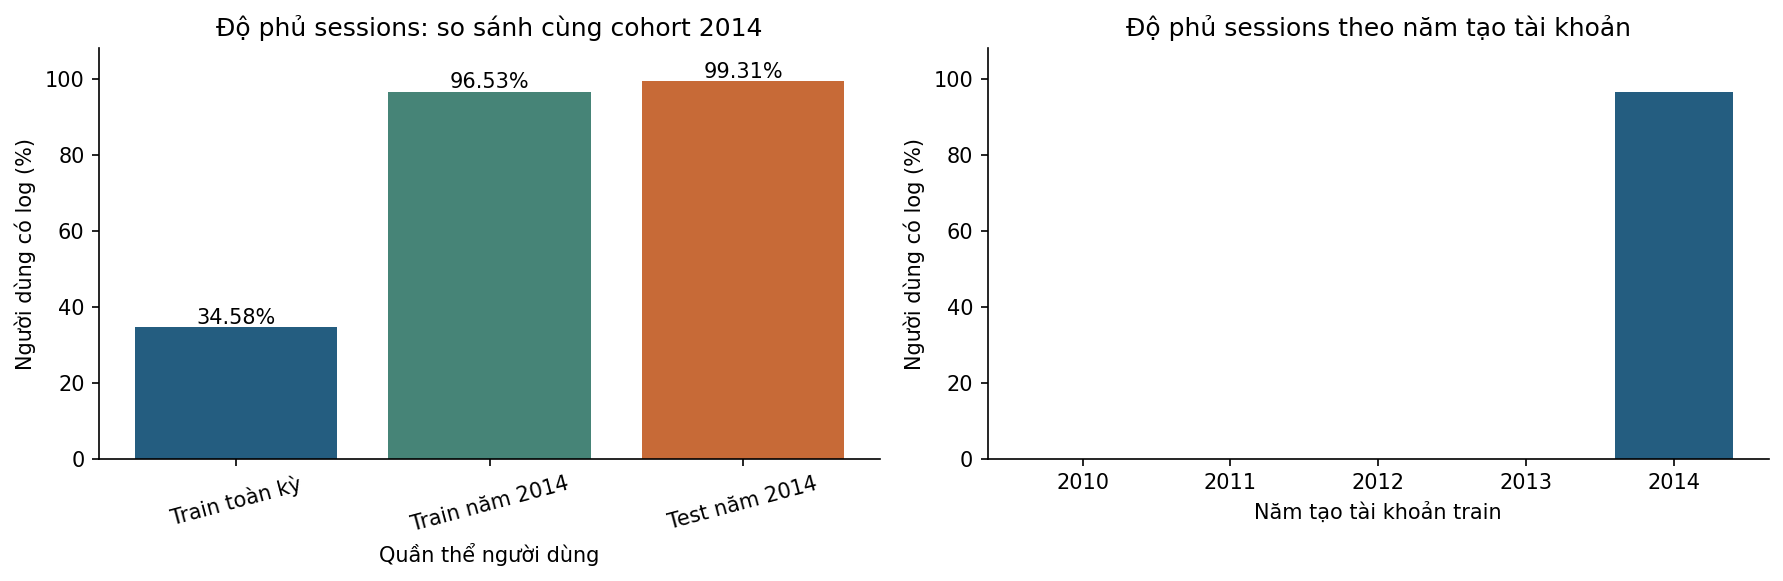

**Quan sát:** độ phủ sessions trên toàn bộ train là 34.58%. Khi giới hạn ở nhóm đăng ký năm 2014, độ phủ train đạt 96.53%, gần hơn với mức 99.31% của test. Khoảng cách còn 2.78 điểm phần trăm. Nhóm đăng ký năm 2010–2013 không có nhật ký, nên tỷ lệ toàn kỳ chịu ảnh hưởng lớn của phạm vi thu thập.

**Phạm vi và cách đọc:** Người dùng trong từng tập và năm đăng ký. Có nhật ký chưa xác định nhật ký có trước t0.

### Nhóm đăng ký tháng có bất định và drift train–test

Train gồm người tạo tài khoản từ tháng 1/2010 đến tháng 6/2014. Test nối tiếp từ tháng 7 đến tháng 9/2014. Hình biểu diễn tỷ lệ đặt chỗ theo từng tháng cùng khoảng Wilson 95%. Vạch tại tháng 1/2014 đánh dấu thời kỳ bắt đầu có sessions. Nhóm tháng ít người có khoảng tin cậy rộng hơn, nên dao động của tỷ lệ cần được đọc cùng cỡ mẫu.

Total variation (TV) đo mức khác nhau giữa hai phân phối của một biến, từ 0 (giống nhau) đến 1 (không giao nhau). Cột tv_all_train_vs_test so sánh toàn bộ train với test. Cột tv_train2014_vs_test giới hạn train ở năm 2014. Nếu TV giảm nhiều trong phép so sánh thứ hai, thành phần năm đăng ký là một yếu tố cần xem xét. Hai phép so sánh mô tả sự thay đổi phân phối đầu vào. Kiểm định mô hình theo thời gian ở phần 7 sẽ đánh giá khả năng dự báo khi dữ liệu thay đổi.

**Khoảng thời gian account**

| population | account min | account max | Số người dùng |
| --- | --- | --- | --- |
| train | 2010-01-01 | 2014-06-30 | 213,451 |
| test | 2014-07-01 | 2014-09-30 | 62,096 |

**Khác biệt category train–test: toàn kỳ và cùng năm 2014**

| Cột gốc | tv all train vs test | test only categories | train missing pct | test missing pct | tv train2014 vs test |
| --- | --- | --- | --- | --- | --- |
| first_device_type | 0.3121 | 0 | 0 | 0 | 0.2337 |
| first_browser | 0.2595 | 3 | 0 | 0 | 0.1848 |
| signup_app | 0.2569 | 0 | 0 | 0 | 0.1534 |
| signup_flow | 0.2201 | 1 | 0 | 0 | 0.1372 |
| affiliate_channel | 0.1574 | 0 | 0 | 0 | 0.1119 |
| gender | 0.0959 | 0 | 0 | 0 | 0.0241 |
| affiliate_provider | 0.092 | 0 | 0 | 0 | 0.0944 |
| first_affiliate_tracked | 0.0798 | 0 | 2.8414 | 0.0322 | 0.0824 |
| signup_method | 0.0419 | 1 | 0 | 0 | 0.0237 |
| language | 0.0137 | 1 | 0 | 0 | 0.0105 |

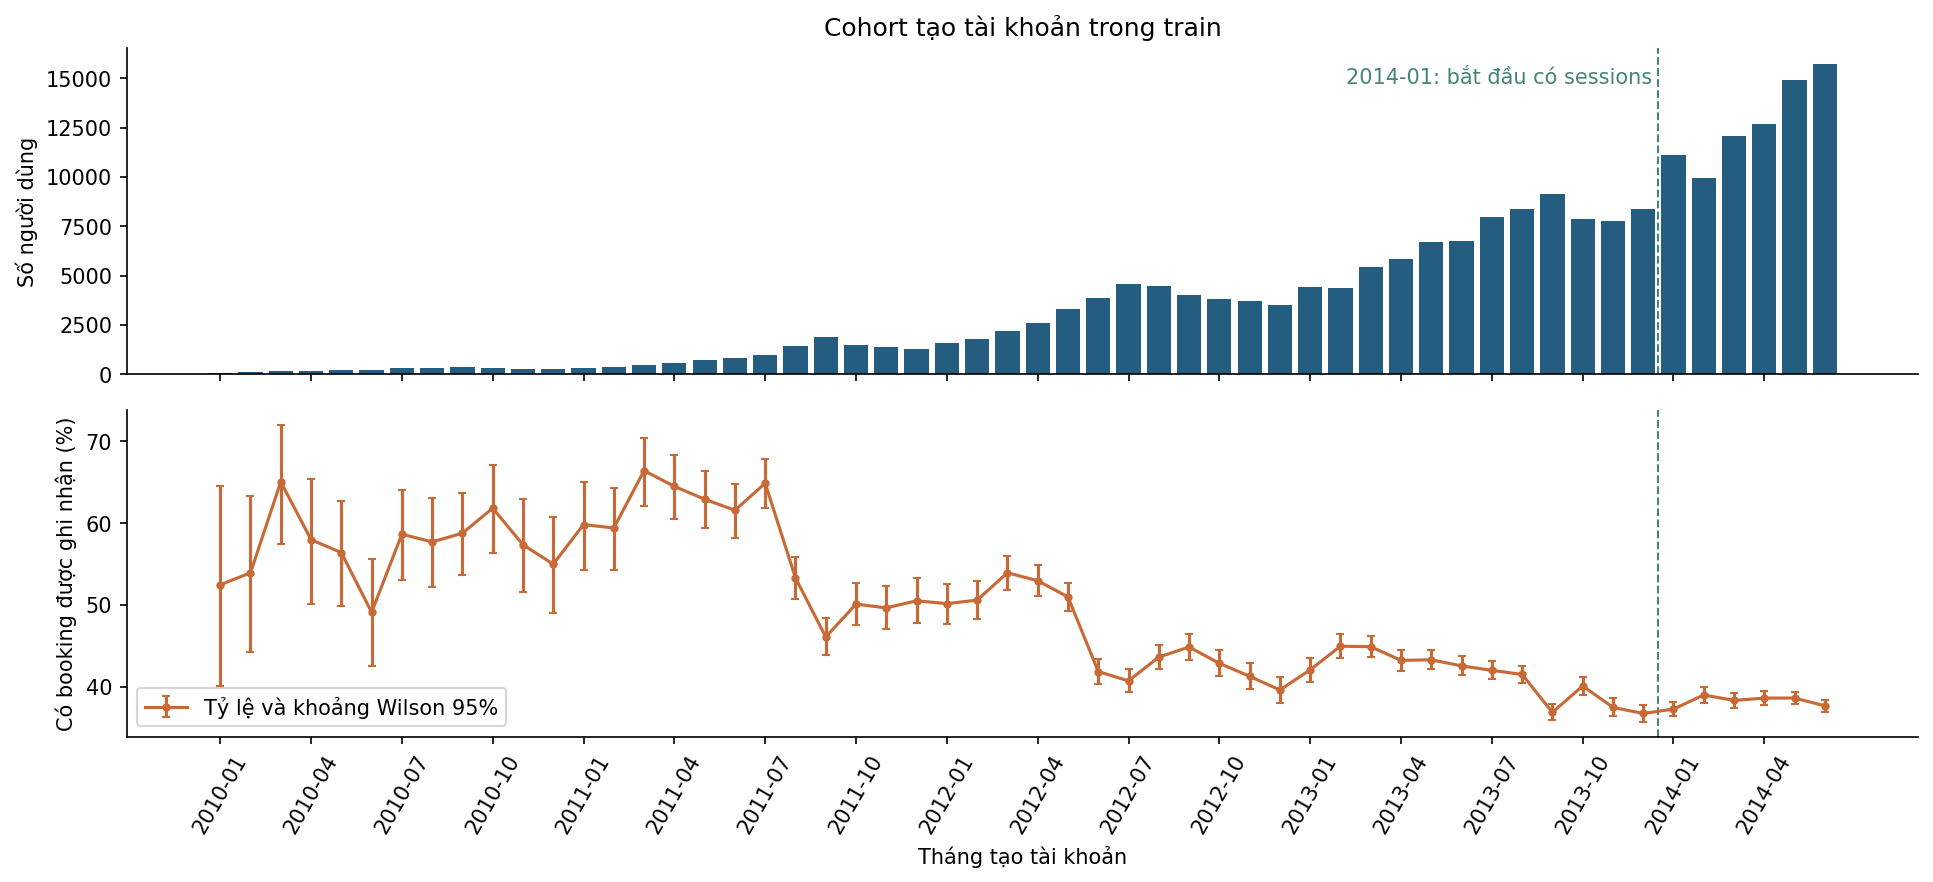

**Quan sát:** nhóm đăng ký tháng 2010-01 chỉ có 61 người. Tỷ lệ đặt chỗ là 52.46% với khoảng Wilson 95% từ 40.16% đến 64.47%. Vì cỡ mẫu nhỏ, ước lượng của tháng này có độ bất định lớn. Vạch đứt tháng 1/2014 đánh dấu thời kỳ bắt đầu có sessions.

**Phạm vi và cách đọc:** Người dùng train theo tháng đăng ký. Khoảng Wilson 95% giả định người dùng độc lập.

In [8]:
eda.show_section(report, 'multivariate_main')

## 6. Tổng hợp giới hạn và mức độ phù hợp

In [9]:
eda.show_section(report, 'risks')

Airbnb phù hợp để nghiên cứu xác suất đặt chỗ đầu tiên tại thời điểm đăng ký. Báo cáo phân biệt nhãn y hiện có với nhãn nghiên cứu y90 dưới giả định theo dõi đủ 365 ngày. Nghiên cứu y90 có thể bắt đầu với giả định được công khai và kiểm tra độ nhạy. Việc triển khai còn cần xác minh hồ sơ tại t0 và cơ chế theo dõi NDF.

**Giới hạn, mức độ phù hợp và điều kiện sử dụng**

| Tiêu chí | Bằng chứng trong báo cáo | Trạng thái | Điều kiện còn lại |
| --- | --- | --- | --- |
| Đủ tín hiệu | 10 category được sàng lọc V; gender V=0.207, trong 2014=0.251; có bảng tương tác/cohort | Đạt ở mức EDA | Kiểm tra giá trị bổ sung so với Logistic Regression mạnh. Các chỉ báo thiếu hồ sơ có liên hệ chồng lặp, không được cộng bằng chứng độc lập. |
| Đủ cỡ mẫu | 213,451 users; 88,908 booking; cohort 2014 76,466 | Đạt tổng thể | Một số category/ô tương tác ít user; dùng n và CI PT/AU và các category hiếm có ít quan sát; khác biệt theo giới/tuổi/kênh có thể bị cohort và missing chi phối. |
| Nhãn tin cậy | Việc có ngày đặt chỗ khớp nhãn y ở 100% trường hợp. Có 29 độ trễ âm và độ trễ tối đa 365 ngày. | Nghiên cứu y90 có điều kiện | Dùng giả định theo dõi 365 ngày và báo độ nhạy. Xác nhận chính thức Q3 trước triển khai; loại 29 ngoại lệ khỏi mẫu y90. |
| Không rò rỉ | date_first_booking và presence tiết lộ nhãn; sessions chứa tên giao dịch, thiếu timestamp | Chưa đạt với toàn bộ raw | Thiết kế chính loại các nguồn này; cần audit lại trước fit date_first_booking tiết lộ nhãn; log không có timestamp nên chưa xác nhận được cửa sổ trước t0. |
| Biến khả dụng tại t0 | t0 đã chọn: sau tạo account; raw không cung cấp lịch sử cập nhật hồ sơ | Cần xác minh | Xác nhận snapshot từng biến; ngày account không có giờ |
| Ổn định theo thời gian | Booking rate/cohort, độ phủ sessions và TV category thay đổi; đã có đối chiếu cùng năm 2014 | Chưa đạt giả định ổn định | Dùng kiểm định theo thời gian, không coi train/test là IID |
| Khái quát hóa | User từ Mỹ, giai đoạn lịch sử; test Kaggle không có nhãn; chưa có dữ liệu vận hành khác | Chưa được chứng minh | Chưa suy sang Việt Nam, thị trường hiện tại hoặc chiến dịch marketing Users từ Mỹ trong giai đoạn lịch sử; thời gian theo dõi từng user chưa xác minh, sessions chỉ phủ cohort 2014. |
| Quyền riêng tư | ID là mã giả danh; age, gender, ngày hoạt động, device và log hành vi vẫn có thể là quasi-identifier. Không nêu ID cá nhân trong báo cáo. | Cần kiểm soát khi sử dụng | Tác giả báo cáo rà soát quyền sử dụng và bảo vệ dữ liệu trước khi chia sẻ hoặc triển khai. |
| Đồng ý / quyền sử dụng | CSV không có biểu mẫu đồng ý hay hồ sơ pháp lý thu thập. Không suy dữ liệu công khai = đồng ý cho mọi mục đích; đọc điều khoản nguồn, không tự gán giấy phép mở. | Cần kiểm soát khi sử dụng | Tác giả báo cáo rà soát quyền sử dụng và bảo vệ dữ liệu trước khi chia sẻ hoặc triển khai. |

### Phát hiện và hàm ý cho bước sau

Mỗi hàm ý nối trực tiếp với quan sát EDA và điều kiện dữ liệu. Các bước mô hình hóa dưới đây là đề xuất cần được kiểm tra bằng thí nghiệm.

**Từ quan sát đến quyết định nghiên cứu**

| Phát hiện | Hàm ý cho bước sau | Điều kiện cần | Bằng chứng trong báo cáo |
| --- | --- | --- | --- |
| Độ trễ tập trung trong 90 ngày | Nghiên cứu nhãn y90 dưới giả định theo dõi 365 ngày | Báo độ nhạy theo Q3; xác nhận cơ chế trước triển khai | Bảng mức bao phủ các thời hạn |
| Cờ thiếu tuổi liên hệ rõ với nhãn y | Đánh giá giá trị bổ sung của tình trạng thiếu hồ sơ | Xác minh tuổi và cờ thiếu tại t0 · Q1 | Bảng độ mạnh liên hệ; bảng tỷ lệ theo nhóm |
| Chênh lệch theo ứng dụng và kênh vẫn có trong năm 2014 | So sánh Logistic Regression và CatBoost | Đánh giá theo thời gian; không suy ra tác động nhân quả | Bảng phân tầng; bản đồ các nhóm kết hợp |
| Ngày đặt chỗ tiết lộ hoàn toàn nhãn y | Loại ngày đặt chỗ và cờ thiếu khỏi danh sách đầu vào | Giữ cột để kiểm tra nhãn, độ trễ và Q2 | Bảng chéo ngày đặt chỗ và nhãn y |
| Nhật ký thiếu thời điểm sự kiện | Loại nhật ký khỏi thiết kế dự đoán ngay sau đăng ký | Chỉ mở nghiên cứu hành vi khi có bằng chứng về thời gian | Bảng rà soát hành động và độ phủ nhật ký |
| Phân phối và tỷ lệ đặt chỗ thay đổi theo thời gian | Dùng các cửa sổ kiểm định liên tiếp | Kiểm tra nhãn đã có sẵn trước từng mốc đánh giá | Bảng tháng đăng ký; bảng khác biệt phân phối |

### Câu hỏi mở và cách xác minh

Ba câu hỏi dưới đây cần bằng chứng ngoài CSV. Vai trò phụ trách là đề xuất cho quy trình nghiên cứu, chưa phải xác nhận rằng cá nhân hoặc tổ chức đã nhận việc. Tác giả báo cáo giữ đầu mối theo dõi và lưu bằng chứng.

Nguồn cần tra cứu gồm [Mô tả dữ liệu](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/data), [Thảo luận Kaggle](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/discussion) và hồ sơ của người cung cấp dữ liệu. Lần tra cứu ngày 2026-11-02 chưa đọc được nội dung trang dữ liệu và thảo luận qua công cụ web. Vì vậy, các liên kết này là nguồn có thể trả lời, không được ghi thành bằng chứng đã xác nhận. Chỉ đóng một câu hỏi khi lưu được liên kết hoặc tài liệu, đoạn giải thích liên quan, ngày đối chiếu và người duyệt.

Q3 đã có bằng chứng định lượng mạnh và không còn chặn việc xây dựng nhãn nghiên cứu 90 ngày có điều kiện. Trạng thái chưa xác nhận chính thức chỉ giới hạn mức kết luận và triển khai.

**Danh mục xác minh và quyết định khi thiếu bằng chứng**

| Câu hỏi | Thông tin cần làm rõ | Nguồn có thể trả lời | Vai trò phụ trách đề xuất | Cách xác minh | Điều kiện kết thúc và quyết định | Trạng thái |
| --- | --- | --- | --- | --- | --- | --- |
| Q1 · Hồ sơ tại t0 | Tuổi, tình trạng thiếu tuổi và các thuộc tính khác là dữ liệu lúc đăng ký hay đã cập nhật về sau? | [Mô tả dữ liệu](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/data); [Thảo luận Kaggle](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/discussion); mô tả trích xuất của người cung cấp dữ liệu | Tác giả báo cáo tổng hợp; người cung cấp dữ liệu xác nhận cách trích xuất; người hướng dẫn duyệt phạm vi | Đối chiếu từ điển gốc và lịch sử cập nhật hoặc mô tả truy vấn trích xuất cho từng thuộc tính. | Lưu bằng chứng về thời điểm có sẵn của từng cột, gồm cả cờ thiếu. Cột chưa có bằng chứng không được coi là đầu vào hợp lệ tại t0. | Mở · chưa có lịch sử hồ sơ |
| Q2 · 29 ngoại lệ ngày đặt chỗ | Vì sao ngày đặt chỗ có trước ngày tạo tài khoản? | [Mô tả dữ liệu](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/data); [Thảo luận Kaggle](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/discussion); giải thích các mốc thời gian từ người cung cấp dữ liệu | Tác giả báo cáo kiểm tra tổng hợp; người cung cấp dữ liệu giải thích; người hướng dẫn duyệt quy tắc xử lý | Đối chiếu ngày hoạt động đầu tiên, quy ước múi giờ, định nghĩa tạo tài khoản và sự kiện đặt chỗ. Lưu bảng kiểm tra tổng hợp, không công bố định danh. | Có giải thích được dẫn nguồn và quyết định giữ hoặc loại có người duyệt. Trong EDA vẫn giữ nguyên dữ liệu và báo riêng 29 trường hợp. | Mở · chưa giải thích được ngoại lệ |
| Q3 · Kết thúc theo dõi | Nhãn y=0 đã được theo dõi đến ngày nào, và vì sao độ trễ lớn nhất là 365 ngày? | [Mô tả dữ liệu](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/data); [Thảo luận Kaggle](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/discussion); quy trình tạo nhãn và ngày kết thúc theo dõi từ người cung cấp dữ liệu | Tác giả báo cáo tổng hợp; người cung cấp dữ liệu xác nhận quy trình tạo nhãn; người hướng dẫn duyệt bài toán | Đối chiếu giới hạn 365 ngày ở mọi nhóm năm và mốc booking cuối. Nghiên cứu dùng giả định theo dõi đủ 365 ngày; đồng thời tìm tài liệu xác nhận NDF thực sự được theo dõi đủ thời hạn. | Cho phép nghiên cứu nhãn y90 có điều kiện ngay; trước triển khai phải lưu xác nhận chính thức cơ chế theo dõi. Báo cả kịch bản bỏ giả định NDF và loại ngoại lệ ngày âm. | Giả thuyết được dữ liệu ủng hộ; đã dùng làm giả định nghiên cứu, chưa xác nhận chính thức |

## 7. Thuật toán và thiết kế đánh giá đề xuất

### Baseline, mô hình chính và xác suất

Thiết kế mô hình dùng nhãn y90 có điều kiện dưới giả định theo dõi đủ 365 ngày. Xác suất hằng chỉ là mốc kiểm tra tối thiểu. Đối chứng quyết định giá trị của CatBoost là Logistic Regression L2 mạnh, gồm một cấu hình ít biến và một cấu hình có cùng đầu vào với CatBoost. Baseline LR được chọn bằng các lượt kiểm định có khoảng đệm, trước khi dùng tập cuối.

Hai cờ hồ sơ có liên hệ mạnh nên cần kiểm tra loại lần lượt cờ thiếu tuổi, cờ không rõ giới tính, rồi ứng dụng đăng ký. Mọi xử lý thiếu, mã hóa và thống kê dựa nhãn chỉ học trên tập học. Chưa huấn luyện mô hình, tính AUC hoặc tối ưu tham số trong báo cáo này.

Bảng entropy bên dưới tính từ tỷ lệ của hai nhóm tuổi trên chính mẫu năm 2014. Đây là phép tính mô tả cùng mẫu, có xu hướng lạc quan, không phải log loss kiểm định hoặc kết quả mô hình. Lift top 20% là kỳ vọng khi chọn ngẫu nhiên trong nhóm có tỷ lệ cao nhất, vì nhóm đó lớn hơn 20% mẫu. Nó cho thấy ngưỡng cũ so với xác suất hằng dễ đạt, nhưng không chứng minh một mô hình đã đạt ngoài thời gian.

**Đối chứng từ đơn giản đến mạnh và so sánh công bằng**

| Ứng viên | Thông tin sử dụng | Vai trò và kiểm soát |
| --- | --- | --- |
| Xác suất hằng | Tỷ lệ y90 trong mỗi tập học | Chỉ là mốc kiểm tra cơ bản |
| Logistic Regression L2 · hồ sơ tối giản | Cờ thiếu tuổi và cờ không rõ giới tính | Đo mức tín hiệu dễ khai thác; kiểm tra bỏ lần lượt từng cờ |
| Logistic Regression L2 · ít biến mạnh | Hai cờ hồ sơ, ứng dụng đăng ký, kênh tiếp cận, cách đăng ký | Baseline mạnh bắt buộc; mã hóa và chọn điều chuẩn trong tập học/kiểm định |
| Logistic Regression L2 · cùng đầu vào | Cùng tập biến hợp lệ tại t0 với CatBoost | So sánh công bằng về nguồn thông tin; baseline chính là LR tốt nhất được chọn trên các lượt kiểm định |
| CatBoost | Cùng thông tin hợp lệ tại t0 | Chỉ chấp nhận nếu tăng giá trị so với LR đã chọn; kiểm tra bỏ cờ hồ sơ và ứng dụng |
| Hiệu chỉnh sigmoid | Áp dụng riêng cho từng ứng viên đã cố định | Cùng cửa sổ hiệu chỉnh, cùng cửa sổ đánh giá; không ưu tiên riêng CatBoost |

**Đối chiếu mô tả: mức tín hiệu chỉ từ tình trạng thiếu tuổi**

| Mục tiêu | Số người dùng · 2014 | Entropy xác suất hằng | Entropy theo hai nhóm tuổi | Giảm entropy cùng mẫu (%) | Lift kỳ vọng top 20% cùng mẫu |
| --- | --- | --- | --- | --- | --- |
| Nhãn y hiện có | 76,466 | 0.6652 | 0.5919 | 11.0149 | 1.4264 |
| Nhãn y90 · giả định 365 ngày | 76,466 | 0.6239 | 0.5789 | 7.2188 | 1.3875 |

... (2 outputs left out)

**B7 · Cửa sổ thời gian đề xuất và quy mô quan sát**

| Mục đích đề xuất | Đăng ký từ ngày | Đăng ký đến ngày | Số người dùng | Mẫu hợp lệ y90 | Số có nhãn y90=1 | Tỷ lệ y90=1 (%) | Mốc dự đoán | Ngày nhãn cửa sổ sẵn có | Vai trò | Đệm từ ngày | Đệm đến ngày | Đệm (ngày lịch) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Lượt 1 · học | 2010-01-01 | 2012-10-02 | 43,308 | 43,282 | 18,370 | 42.4426 | 2013-01-01 | 2013-01-01 | học | 2012-10-03 | 2012-12-31 | 90 |
| Lượt 1 · kiểm định | 2013-01-01 | 2013-03-31 | 14,201 | 14,200 | 5,211 | 36.6972 | 2013-01-01 | 2013-06-30 | kiểm định | — | — | 0 |
| Lượt 2 · học | 2010-01-01 | 2013-04-01 | 68,434 | 68,405 | 27,252 | 39.8392 | 2013-07-01 | 2013-07-01 | học | 2013-04-02 | 2013-06-30 | 90 |
| Lượt 2 · kiểm định | 2013-07-01 | 2013-08-31 | 16,319 | 16,319 | 5,703 | 34.947 | 2013-07-01 | 2013-11-30 | kiểm định | — | — | 0 |
| Lượt 3 · học | 2010-01-01 | 2013-06-02 | 81,150 | 81,121 | 31,877 | 39.2956 | 2013-09-01 | 2013-09-01 | học | 2013-06-03 | 2013-08-31 | 90 |
| Lượt 3 · kiểm định | 2013-09-01 | 2013-10-02 | 9,833 | 9,833 | 2,928 | 29.7773 | 2013-09-01 | 2014-01-01 | kiểm định | — | — | 0 |
| Huấn luyện lại | 2010-01-01 | 2013-10-02 | 113,719 | 113,690 | 42,836 | 37.6779 | 2014-01-01 | 2014-01-01 | học | 2013-10-03 | 2013-12-31 | 90 |
| Hiệu chỉnh xác suất | 2014-01-01 | 2014-01-30 | 10,774 | 10,774 | 3,248 | 30.1466 | 2014-01-01 | 2014-05-01 | hiệu chỉnh | 2014-01-31 | 2014-04-30 | 90 |
| Đánh giá cuối | 2014-05-01 | 2014-06-30 | 30,641 | 30,641 | 9,712 | 31.6961 | 2014-05-01 | 2014-09-29 | đánh giá | — | — | 0 |

**Vai trò từng giai đoạn huấn luyện, hiệu chỉnh và đánh giá**

| Giai đoạn | Cửa sổ | Thời điểm và điều kiện sử dụng |
| --- | --- | --- |
| Chọn cấu hình | Ba lượt kiểm định trong năm 2013 | Nhãn lượt cuối sẵn có từ 2014-01-01; lúc đó mới chốt mô hình và LR đối chứng |
| Huấn luyện lại | Người đăng ký đến 2013-10-02 | Đệm 2013-10-03 đến 2013-12-31; dự đoán hiệu chỉnh từ 2014-01-01 |
| Hiệu chỉnh | Người đăng ký 2014-01-01 đến 2014-01-30 | Đệm 2014-01-31 đến 2014-04-30; mô hình nền giữ cố định |
| Đánh giá cuối | Người đăng ký 2014-05-01 đến 2014-06-30 | Mô hình và bộ hiệu chỉnh cố định trước 2014-05-01; kết quả hoàn tất từ 2014-09-29 |
| Test Kaggle | Người đăng ký tháng 7–9/2014 | Chỉ kiểm tra cấu trúc và thay đổi phân phối vì không có nhãn |

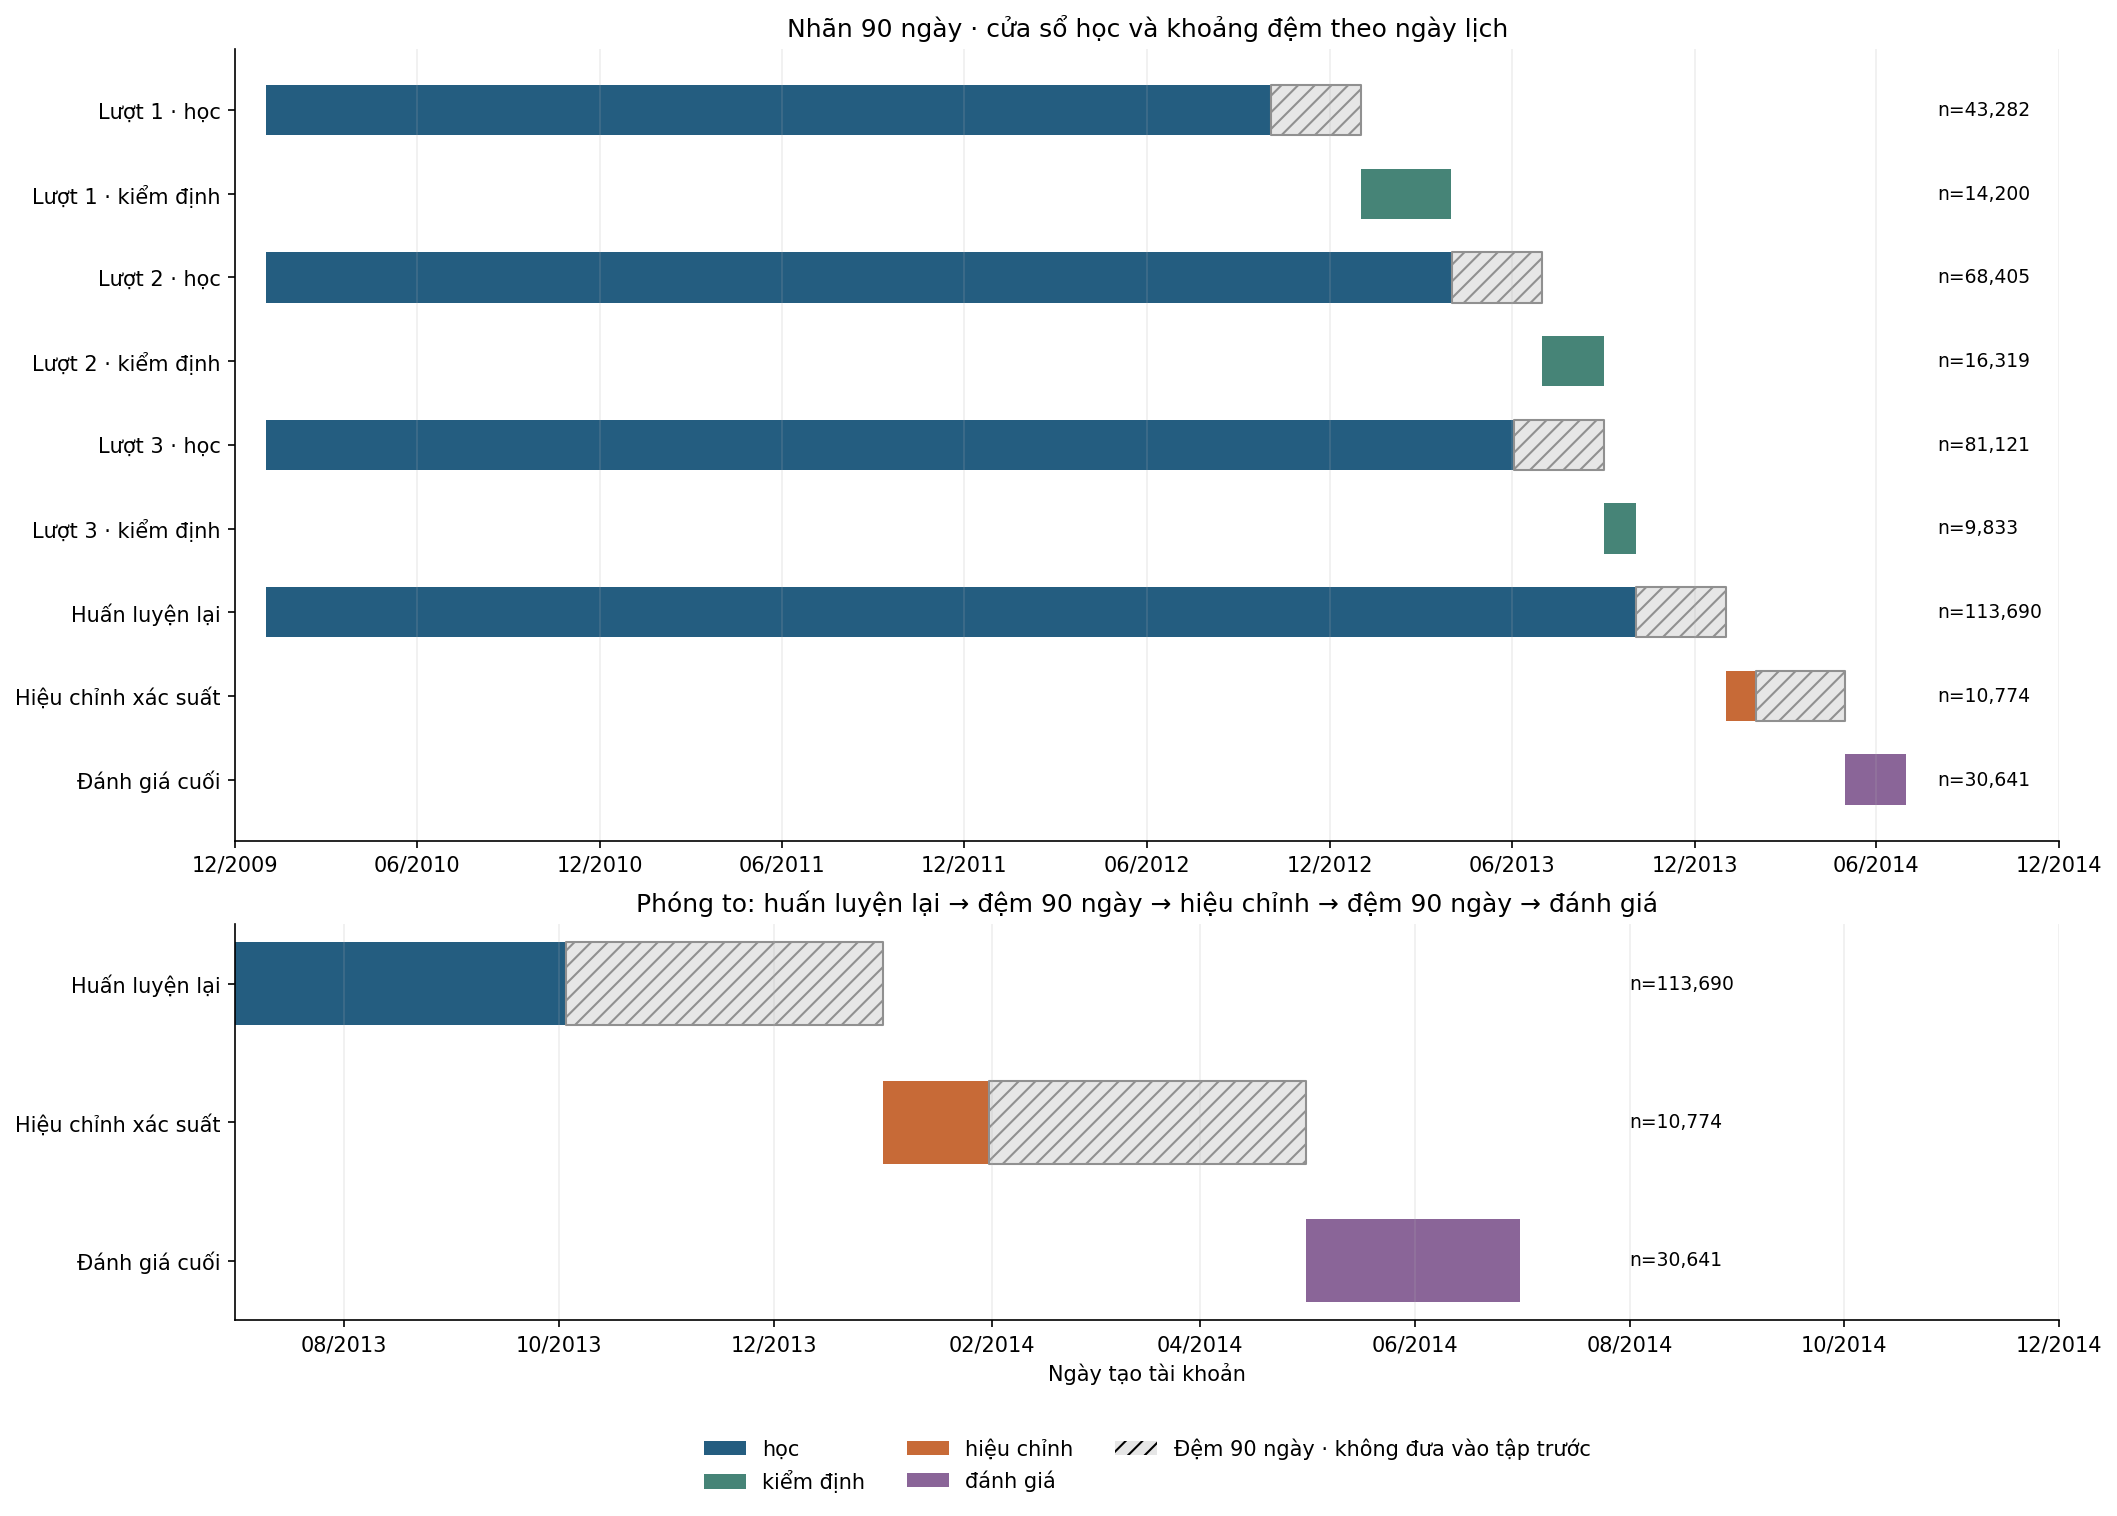

**Quan sát:** mỗi tập học cách tập kiểm định hoặc hiệu chỉnh một khoảng đệm 90 ngày. Hiệu chỉnh dùng người đăng ký 2014-01-01 đến 2014-01-30, rồi chờ đến 2014-05-01 mới bắt đầu đánh giá cuối.

**Phạm vi và cách đọc:** thanh màu là cửa sổ ngày đăng ký; vùng gạch là khoảng đệm không đưa vào tập trước. Cỡ mẫu loại ngoại lệ chưa gán y90. Ngày nhãn sẵn có dùng quy tắc ngày đăng ký cuối + 91, tương đương ngày thứ 90 hoàn tất trước mốc dự đoán. Toàn bộ nhãn y90 vẫn có điều kiện trên giả định theo dõi đủ 365 ngày.

### Tiêu chí chấp nhận đặt trước

Các ngưỡng dưới đây là đề xuất đặt trước cho giá trị bổ sung của CatBoost so với Logistic Regression mạnh. Chúng không phải kết quả đã đo hoặc chuẩn phổ quát. Thay đổi đối chứng là điểm chính; chỉ tăng một ngưỡng so với xác suất hằng vẫn chưa đủ. Mức giảm log loss 2% so với hằng và lift tuyệt đối 1.20 của bản trước không còn dùng để chấp nhận CatBoost. Chọn LR đối chứng và bộ tham số bằng dữ liệu phát triển, không chọn theo tập cuối.

**Điều kiện để CatBoost được chấp nhận thay cho LR**

| Tiêu chí | Điều kiện chấp nhận đề xuất | Cách diễn giải |
| --- | --- | --- |
| Toàn vẹn và thời gian | 0 ID giao nhau trong mỗi lượt; ngày đăng ký + 90 < mốc dự đoán cho mọi nhãn dùng học; loại 29 ngoại lệ khỏi y90 | Kiểm tra cả học, hiệu chỉnh và thời điểm chọn cấu hình |
| Giá trị bổ sung · tiêu chí chính | Log loss CatBoost giảm ít nhất 1% tương đối so với baseline LR mạnh đã chọn; cận trên 95% của chênh log loss (CatBoost − LR) < 0 | So sánh ghép cặp trên cùng người, cùng mẫu y90 và cùng hiệu chỉnh; bootstrap theo người dùng |
| Ưu tiên top 20% | Lift@20% tăng ít nhất 5% tương đối so với LR; cận dưới 95% của chênh lift > 0 | Ngân sách 20% và mức 5% là đề xuất nghiên cứu; ngưỡng tuyệt đối 1.20 chỉ còn là thông tin tham khảo |
| Phân biệt và xác suất | AP không thấp hơn LR trên điểm ước lượng; báo ROC-AUC, Brier và độ hiệu chỉnh cho cả hai | Brier không kém LR quá 0.002 tuyệt đối; báo khoảng tin cậy của chênh lệch |
| Hiệu chỉnh | Báo sai lệch xác suất trung bình, ECE 10 nhóm đồng số mẫu và biểu đồ độ tin cậy cho cả LR và CatBoost | Không lấy riêng log loss hoặc ECE làm bằng chứng đầy đủ về hiệu chỉnh |
| Độ bền và chồng lặp tín hiệu | Báo chênh log loss với LR trong từng tháng và từng nhóm đủ/thiếu hồ sơ; kiểm tra bỏ từng cờ và ứng dụng | Nếu giá trị bổ sung không ổn định hoặc không đạt, ưu tiên LR đơn giản hơn |

In [10]:
eda.show_section(report, 'research_design')

## Phụ lục — từ điển và bảng bổ sung

In [11]:
eda.show_section(report, 'appendix')

### Từ điển users và quan hệ giữa các bảng

`id` là khóa users, ghép một–nhiều với `sessions.user_id`. Cần phân tích users trước và sau ghép mà không làm một người dùng bị nhân thành nhiều quan sát học. `countries` có khóa quốc gia; không ghép bằng điểm đến thật để dự đoán chính nhãn đó. `age_gender_bkts` là thống kê tổng hợp theo bucket/quốc gia/giới tính, không phải thêm 420 khách hàng.

**Schema đầy đủ của train users**

| Cột gốc | Kiểu dữ liệu | Số giá trị khác nhau không thiếu | Số thiếu | Tỷ lệ thiếu (%) | Ý nghĩa | Lưu ý | Vai trò | Đơn vị | Miền giá trị và căn cứ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| id | object | 213,451 | 0 | 0 | Định danh người dùng | Khóa ghép sessions.user_id; không phải phép đo | định danh / khóa nhóm, không phải số liên tục | mã/nhãn phân loại, không có đơn vị vật lý | Khóa/mã; không in giá trị định danh cá nhân trong báo cáo |
| date_account_created | object | 1,634 | 0 | 0 | Ngày tạo tài khoản | Mốc cohort; không tự xác định horizon nhãn | ứng viên hồ sơ tại signup; cần xác minh snapshot | ngày/giờ theo định dạng nguồn; timezone chưa xác minh | Toàn bảng: 2010-01-01–2014-06-30 |
| timestamp_first_active | int64 | 213,451 | 0 | 0 | Lần hoạt động đầu, dạng YYYYMMDDHHMMSS | Có thể trước ngày tạo tài khoản; cần parse theo định dạng | ứng viên hồ sơ tại signup; cần xác minh snapshot | ngày/giờ theo định dạng nguồn; timezone chưa xác minh | Toàn bảng: [2.00903e+13, 2.01406e+13], 213451 giá trị phân biệt |
| date_first_booking | object | 1,976 | 124,543 | 58.3473 | Ngày của lượt đặt chỗ đầu tiên | Kết quả. Việc có giá trị hay bị thiếu tiết lộ nhãn y. | kết quả; loại khỏi đầu vào tại signup | ngày/giờ theo định dạng nguồn; timezone chưa xác minh | Toàn bảng: 2010-01-02–2015-06-29 |
| gender | object | 4 | 0 | 0 | Giới tính khai báo | -unknown- là sentinel, không phải giá trị biết rõ | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: '-unknown-', 'FEMALE', 'MALE', 'OTHER' |
| age | float64 | 127 | 87,990 | 41.2226 | Tuổi khai báo | Thiếu và giá trị ngoài dải tham chiếu; chưa sửa tuổi/năm sinh | ứng viên hồ sơ tại signup; cần xác minh snapshot | năm tuổi khai báo | Toàn bảng: [1; 2014], 127 giá trị phân biệt |
| signup_method | object | 3 | 0 | 0 | Phương thức đăng ký | Biến phân loại | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'basic', 'facebook', 'google' |
| signup_flow | int64 | 17 | 0 | 0 | Mã luồng/trang đăng ký | Mã phân loại dù pandas đọc số | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: [0; 25], 17 giá trị phân biệt |
| language | object | 25 | 0 | 0 | Ngôn ngữ ưu tiên | Biến phân loại | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 25 giá trị khác nhau; top category tại phụ lục |
| affiliate_channel | object | 8 | 0 | 0 | Kênh marketing liên quan | Không tự chứng minh tác động nhân quả của kênh | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'api', 'content', 'direct', 'other', 'remarketing', 'sem-brand', 'sem-non-brand', 'seo' |
| affiliate_provider | object | 18 | 0 | 0 | Nhà cung cấp/kênh cụ thể | Biến phân loại | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 18 giá trị khác nhau; top category tại phụ lục |
| first_affiliate_tracked | object | 7 | 6,065 | 2.8414 | Tương tác affiliate đầu được theo dõi | NA và category untracked có nghĩa khác nhau | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'linked', 'local ops', 'marketing', 'omg', 'product', 'tracked-other', 'untracked' |
| signup_app | object | 4 | 0 | 0 | Ứng dụng đăng ký | Không đại diện mọi thiết bị dùng về sau | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'Android', 'Moweb', 'Web', 'iOS' |
| first_device_type | object | 9 | 0 | 0 | Thiết bị đầu tiên | Khác device_type ở từng sự kiện sessions | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'Android Phone', 'Android Tablet', 'Desktop (Other)', 'Mac Desktop', 'Other/Unknown', 'SmartPhone (Other)', 'Windows Desktop', 'iPad', 'iPhone' |
| first_browser | object | 52 | 0 | 0 | Trình duyệt đầu tiên | Có sentinel -unknown- | ứng viên hồ sơ tại signup; cần xác minh snapshot | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 52 giá trị khác nhau; top category tại phụ lục |
| country_destination | object | 12 | 0 | 0 | Điểm đến của lượt đặt chỗ đầu tiên hoặc NDF | Cột điểm đến có 12 giá trị, được dùng để định nghĩa nhãn y. | đích | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'AU', 'CA', 'DE', 'ES', 'FR', 'GB', 'IT', 'NDF', 'NL', 'PT', 'US', 'other' |

**So sánh schema train và test**

| Cột gốc | Có trong train | Có trong test |
| --- | --- | --- |
| id | 1 | 1 |
| date_account_created | 1 | 1 |
| timestamp_first_active | 1 | 1 |
| date_first_booking | 1 | 1 |
| gender | 1 | 1 |
| age | 1 | 1 |
| signup_method | 1 | 1 |
| signup_flow | 1 | 1 |
| language | 1 | 1 |
| affiliate_channel | 1 | 1 |
| affiliate_provider | 1 | 1 |
| first_affiliate_tracked | 1 | 1 |
| signup_app | 1 | 1 |
| first_device_type | 1 | 1 |
| first_browser | 1 | 1 |
| country_destination | 1 | 0 |

... (116 outputs left out)

### Truy vết số liệu trong tóm tắt

Mã B1–B11 đứng trước tên các bảng tương ứng. Các số được làm tròn khi trình bày. Metadata giữ giá trị đầy đủ trong facts và dấu kiểm tra của các bảng thống kê. Các mốc chia thời gian là đề xuất nghiên cứu, không phải kết quả đã thực hiện.

**Nguồn của từng phát hiện và việc cần giải quyết**

| Ý trong tóm tắt | Bảng hoặc câu hỏi nguồn | Số liệu và nội dung được đối chiếu | Đường dẫn dữ liệu hoặc cách tính |
| --- | --- | --- | --- |
| Phát hiện 1 | B1 | Quy mô train, test, số và tỷ lệ nhãn y=1 | facts.rows; facts.test_rows; facts.positive; facts.rate |
| Phát hiện 2 | B9 | Số dương trong 90 ngày, tỷ lệ trên toàn bộ dòng và mẫu hợp lệ sau khi bỏ ngoại lệ | facts.conditional_90_positive; facts.conditional_90_eligible; facts.conditional_90_rate_pct |
| Phát hiện 3 | B10 | Tỷ lệ đặt chỗ theo giới tính, tình trạng tuổi và V giữa hai cờ thiếu | profile_summary: nhãn y và V giữa chỉ báo đầu vào trong năm 2014 |
| Phát hiện 4 | B11 | Chênh lệch ứng dụng trong nhóm có tuổi và có khai báo giới tính | profile_apps: age_missing=False; gender_unknown=False; source_rate |
| Phát hiện 5 | B5 | Độ phủ, chênh độ phủ, tỷ lệ đặt chỗ có/thiếu nhật ký; quy mô train 2014 | facts.train_2014_users; facts.train_2014_session_coverage_pct; sessions_2014 |
| Việc cần giải quyết 1 | B9; Q3 | Nghiên cứu y90 với giả định theo dõi 365 ngày, ngoại lệ và độ nhạy NDF | Quy tắc conditional_labels và bảng nhạy cảm với giả định |
| Việc cần giải quyết 2 | B8; Q1 | Mức khớp 100% và điều kiện thông tin tại t0 | Tính trực tiếp từ ngày đặt chỗ có giá trị và nhãn y |
| Việc cần giải quyết 3 | B7 | Huấn luyện đến 2013-10-02; hiệu chỉnh 2014-01-01 đến 2014-01-30; đệm 90 ngày; đánh giá tháng 5–6/2014 | protocol: cửa sổ, mốc dự đoán, ngày nhãn sẵn có và đệm theo ngày lịch |

## Tái lập và kiểm soát phạm vi

In [12]:
eda.show_section(report, 'reproducibility')

Để chạy lại notebook, cần thư mục scripts/ và năm CSV train_users_2.csv, test_users.csv, sessions.csv, countries.csv, age_gender_bkts.csv tại data/raw/AIRBNB/. Notebook đã lưu kết quả để đọc trực tiếp. Dữ liệu gốc được lấy riêng theo hướng dẫn vì không được đính kèm kho mã.

Cài môi trường EDA từ thư mục gốc bằng lệnh dưới đây. Đây là hướng dẫn chuẩn bị, không phải ô phân tích dữ liệu:

```powershell
python -m pip install pandas==2.3.3 numpy==2.4.1 scipy==1.17.1 matplotlib==3.10.8 nbformat==5.10.4 ipython==9.9.0 tzdata
```

Từ thư mục gốc, chạy `python scripts/build_descriptive_reports.py --dataset AIRBNB`. Cách khác là mở notebook bằng Jupyter, chọn Restart Kernel rồi Run All. Script đọc CSV gốc và xuất báo cáo Markdown, metadata JSON, hình và notebook có kết quả thực thi.

**Hồ sơ dự án chưa có bằng chứng về ngày tải và mã phiên bản Kaggle.** Báo cáo để trạng thái chưa xác định và nhận diện bản dữ liệu đang dùng bằng SHA-256 của từng file cùng danh mục file trong metadata. Ngày phân tích được ghi theo múi giờ Asia/Ho_Chi_Minh và không thay thế ngày tải.

Các bảng dùng toàn bộ người dùng hoặc toàn bộ sessions có khóa hợp lệ trong phạm vi ghi cạnh bảng. Hình về mẫu thiếu chỉ hiển thị tối đa 300 dòng với seed=42.

Phép tính Cramér V dùng chi-square không hiệu chỉnh Yates. Bảng báo p-value xấp xỉ và tỷ lệ ô có tần số kỳ vọng dưới 5 để kiểm tra độ phù hợp của xấp xỉ. Kiểm định Mann–Whitney hai phía dùng xấp xỉ có hiệu chỉnh các giá trị đồng hạng. Hệ số rank-biserial được tính bằng 2U/(n_y1 × n_y0) − 1. Trong công thức này, U là thống kê Mann–Whitney với nhóm y=1 đứng trước, còn n_y1 và n_y0 là cỡ mẫu hai nhóm.

Phương pháp Benjamini–Hochberg (BH) điều chỉnh p-value cho 14 phép kiểm định trên toàn kỳ và cho ra giá trị q trong bảng. Việc chọn biến sẽ được kiểm tra bằng thí nghiệm mô hình. Khoảng Wilson 95% giả định các người dùng độc lập. Khoảng này mô tả bất định của tỷ lệ, đồng thời cần xem xét riêng sai lệch chọn mẫu và khác biệt giữa các nhóm đăng ký.

Các kết quả được tính lại trong lần phân tích hiện tại. Bảng môi trường dưới đây và SHA-256 của ba module dựng báo cáo trong metadata nhận diện mã đã chạy. Thuật toán, cửa sổ chia dữ liệu, bootstrap và ngưỡng chấp nhận ở phần 7 là thiết kế cho giai đoạn tiếp theo.

Mỗi giai đoạn 0–4 được dựng lại toàn bộ từ CSV bằng cùng notebook. Khi xuất báo cáo, chương trình đối chiếu các số liệu chính với metadata trước đó và kiểm tra SHA-256 của các bảng bằng chứng. Sau khi mọi ô chạy thành công, completed_stages trong metadata ghi kết quả của giai đoạn đó. Đây là lịch sử kiểm tra trong cùng bản báo cáo, không tạo bản sao, tag hay nhánh khác.

**Môi trường thực thi chính xác**

| Thành phần | Giá trị |
| --- | --- |
| Python | 3.14.2 |
| pandas | 2.3.3 |
| numpy | 2.4.1 |
| matplotlib | 3.10.8 |
| Phương pháp | Thống kê mô tả, không mô hình |
| Chunk CSV lớn | 250000 |
| scipy | 1.17.1 |
| nbformat | 5.10.4 |
| IPython | 9.9.0 |

**Điều kiện hoàn thành và kiểm tra sau từng giai đoạn**

| Giai đoạn | Điều kiện hoàn thành | Cách kiểm tra |
| --- | --- | --- |
| 0 · Sửa nội dung | Đủ cảnh báo mẫu số và t0; số thập phân thống nhất; không lặp từ; mở đầu không có lệnh cài; ngày tải ghi đúng bằng chứng | Kiểm tra văn bản, notebook và metadata |
| 1 · Chuẩn hóa | Mỗi hình có quan sát và phạm vi; tiêu đề bảng dùng tên diễn giải; khái niệm có tên thống nhất; phương pháp chi tiết ở cuối | Kiểm tra chú thích, tiêu đề và bảng thuật ngữ |
| 2 · Tổ chức EDA | Có biểu đồ độ mạnh liên hệ với hai thang riêng; tỷ lệ nhóm có khoảng Wilson; bảng dài nằm ở phụ lục | Kiểm tra hình, bảng và dấu kiểm tra thống kê |
| 3 · Hiểu dữ liệu | Có quyết định cho toàn bộ 34 cột; sơ đồ quan hệ; phát hiện gắn hàm ý; rủi ro và phù hợp gộp một mục | Đối chiếu số cột CSV, cấu trúc báo cáo và bảng quyết định |
| 4 · Thiết kế nghiên cứu | Có sơ đồ thời gian và vai trò từng giai đoạn; mọi số trong tóm tắt có bảng nguồn; notebook chạy hết; số liệu khớp sau từng giai đoạn | Đối chiếu B1–B8, nguồn số liệu, lịch sử kiểm tra và mã nguồn trong metadata |